In [2]:
# Mumbai & Thane Real Estate Investment Analysis
# Comprehensive analysis of property data for investment insights

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('default')
sns.set_palette("husl")

# Load the data
df = pd.read_csv('../data/raw/mumbai_thane_realestate.csv')

# Display basic information about the dataset
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nFirst few rows:")
df.head()

Dataset Shape: (12685, 145)

Column Names:
['ID', 'Possession Status', 'Availability Starts From', 'Floor No', 'Commercial', 'Developer', 'Approved Authority Name', 'Units Available', 'Price', 'Price (English)', 'Flooring Type', 'Electricity Status', 'Maintenance Type', 'Maintenance Charges', 'Booking Amount', 'Landmark', 'Covered Area', 'Project Name', 'sqft Price ', 'Carpet Area', 'Area Name', 'Property Uniqueness', 'Unit of Carpet Area', 'Society', 'Ownership Type', 'furnished Type', 'Bathroom', 'Parking', 'Facing', 'Amenities Facing', 'Transaction Type', 'Floor Data', 'Type of Property', 'City', 'bedroom', 'Data Referred From', 'floors', 'Water Status', 'Luxury Flat', 'Covered Area.1', 'Carpet Area Unit', 'isPrimeLocationProperty', 'Tenants Preference', 'Location', 'Property', 'covArea Unit', 'isLuxuryServiceProvided', 'Property Lifespan', 'balconies', 'Rera', 'Power Back Up', 'Lift', 'Rain Water Harvesting', 'Club House', 'Swimming Pool', 'Gymnasium', 'Park', 'Parking.1', 'Securit

,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
0,12685,Under Construction,Dec '25,5,N,NaN,KDMC,1.0,3150000.0,31.5 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
1,12684,Ready to Move,NaN,20,Y,TATA Housing Development Company Ltd.,TMC,10.0,6300000.0,63 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
2,12683,Ready to Move,NaN,18,N,Sai Satyam Developers,KDMC,0.0,5400000.0,54 Lac,...,1,1,1,1,1,NaN,Y,NaN,NaN,NaN
3,12682,Under Construction,Dec '25,5,N,Birla Estates,KDMC,70.0,9000000.0,90 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
4,12681,Under Construction,Dec '24,8,Y,Godrej Properties,NaN,NaN,4950000.0,49.5 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN


In [4]:
# Data Cleaning and Preprocessing
print("Data Cleaning Phase")
print("==================")

# Check for missing values in key columns
print("\nMissing values in key columns:")
key_columns = ['Price', 'City', 'Carpet Area', 'Developer', 'Possession Status', 
               'isPrimeLocationProperty', 'Type of Property', 'bedroom']
for col in key_columns:
    if col in df.columns:
        print(f"{col}: {df[col].isnull().sum()}")

# Clean Price column - remove commas and convert to numeric
df['Price_Clean'] = df['Price'].astype(str).str.replace(',', '').astype(float)

# Clean Carpet Area - handle missing values and convert to numeric
df['Carpet_Area_Clean'] = pd.to_numeric(df['Carpet Area'], errors='coerce')

# Clean sqft Price column
df['sqft_Price_Clean'] = pd.to_numeric(df['sqft Price '], errors='coerce')

# Calculate price per sqft where missing
mask_missing_sqft_price = df['sqft_Price_Clean'].isnull()
mask_has_carpet_area = df['Carpet_Area_Clean'].notna()
calculate_mask = mask_missing_sqft_price & mask_has_carpet_area

df.loc[calculate_mask, 'sqft_Price_Clean'] = (
    df.loc[calculate_mask, 'Price_Clean'] / df.loc[calculate_mask, 'Carpet_Area_Clean']
)

# Create bedroom category
df['Bedroom_Category'] = df['bedroom'].fillna(0).astype(int).astype(str) + ' BHK'

# Filter for Mumbai and Thane
df_filtered = df[df['City'].isin(['Mumbai', 'Thane'])].copy()

print(f"\nData after filtering for Mumbai and Thane: {df_filtered.shape[0]} properties")
print(f"Mumbai properties: {sum(df_filtered['City'] == 'Mumbai')}")
print(f"Thane properties: {sum(df_filtered['City'] == 'Thane')}")

# Display summary statistics
print("\nPrice statistics (in Lakhs):")
print(df_filtered['Price_Clean'].describe() / 100000)

df_filtered.head()

Data Cleaning Phase

Missing values in key columns:
Price: 84
City: 0
Carpet Area: 2552
Developer: 5679
Possession Status: 78
isPrimeLocationProperty: 0
Type of Property: 0
bedroom: 0

Data after filtering for Mumbai and Thane: 12655 properties
Mumbai properties: 8542
Thane properties: 4113

Price statistics (in Lakhs):
count         0.125710
mean        264.538842
std        3657.990345
min           1.000000
25%          70.000000
50%         135.000000
75%         255.000000
max      408000.000010
Name: Price_Clean, dtype: float64


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type,Price_Clean,Carpet_Area_Clean,sqft_Price_Clean,Bedroom_Category
0,12685,Under Construction,Dec '25,5,N,NaN,KDMC,1.0,3150000.0,31.5 Lac,...,1,NaN,NaN,NaN,NaN,NaN,3150000.0,375.0,4960.0,1 BHK
1,12684,Ready to Move,NaN,20,Y,TATA Housing Development Company Ltd.,TMC,10.0,6300000.0,63 Lac,...,1,NaN,NaN,NaN,NaN,NaN,6300000.0,579.0,10880.0,2 BHK
2,12683,Ready to Move,NaN,18,N,Sai Satyam Developers,KDMC,0.0,5400000.0,54 Lac,...,1,NaN,Y,NaN,NaN,NaN,5400000.0,585.0,6352.0,2 BHK
3,12682,Under Construction,Dec '25,5,N,Birla Estates,KDMC,70.0,9000000.0,90 Lac,...,1,NaN,NaN,NaN,NaN,NaN,9000000.0,815.0,8571.0,2 BHK
4,12681,Under Construction,Dec '24,8,Y,Godrej Properties,NaN,NaN,4950000.0,49.5 Lac,...,1,NaN,NaN,NaN,NaN,NaN,4950000.0,419.0,8824.0,1 BHK


1. PRICE SEGMENTATION & MARKET OVERVIEW
Price Segment Thresholds:
Budget: ≤ ₹88.0 Lakhs
Mid-Range: ₹88.0 - ₹200.0 Lakhs
Premium: > ₹200.0 Lakhs

Price Segment Distribution by City:
                       Count    Avg_Price  Avg_Carpet_Area  \
Price_Segment  City                                          
Budget (Low)   Mumbai   2064   4940400.88           454.68   
               Thane    2114   5445088.96           487.39   
Mid-Range      Mumbai   2704  14386920.80           597.96   
               Thane    1598  13095158.83           747.36   
Premium (High) Mumbai   3727  64209894.83          1249.49   
               Thane     364  32157409.34          1278.18   

                      Common_Property_Type  
Price_Segment  City                         
Budget (Low)   Mumbai            Apartment  
               Thane             Apartment  
Mid-Range      Mumbai            Apartment  
               Thane             Apartment  
Premium (High) Mumbai            Apartment  
       

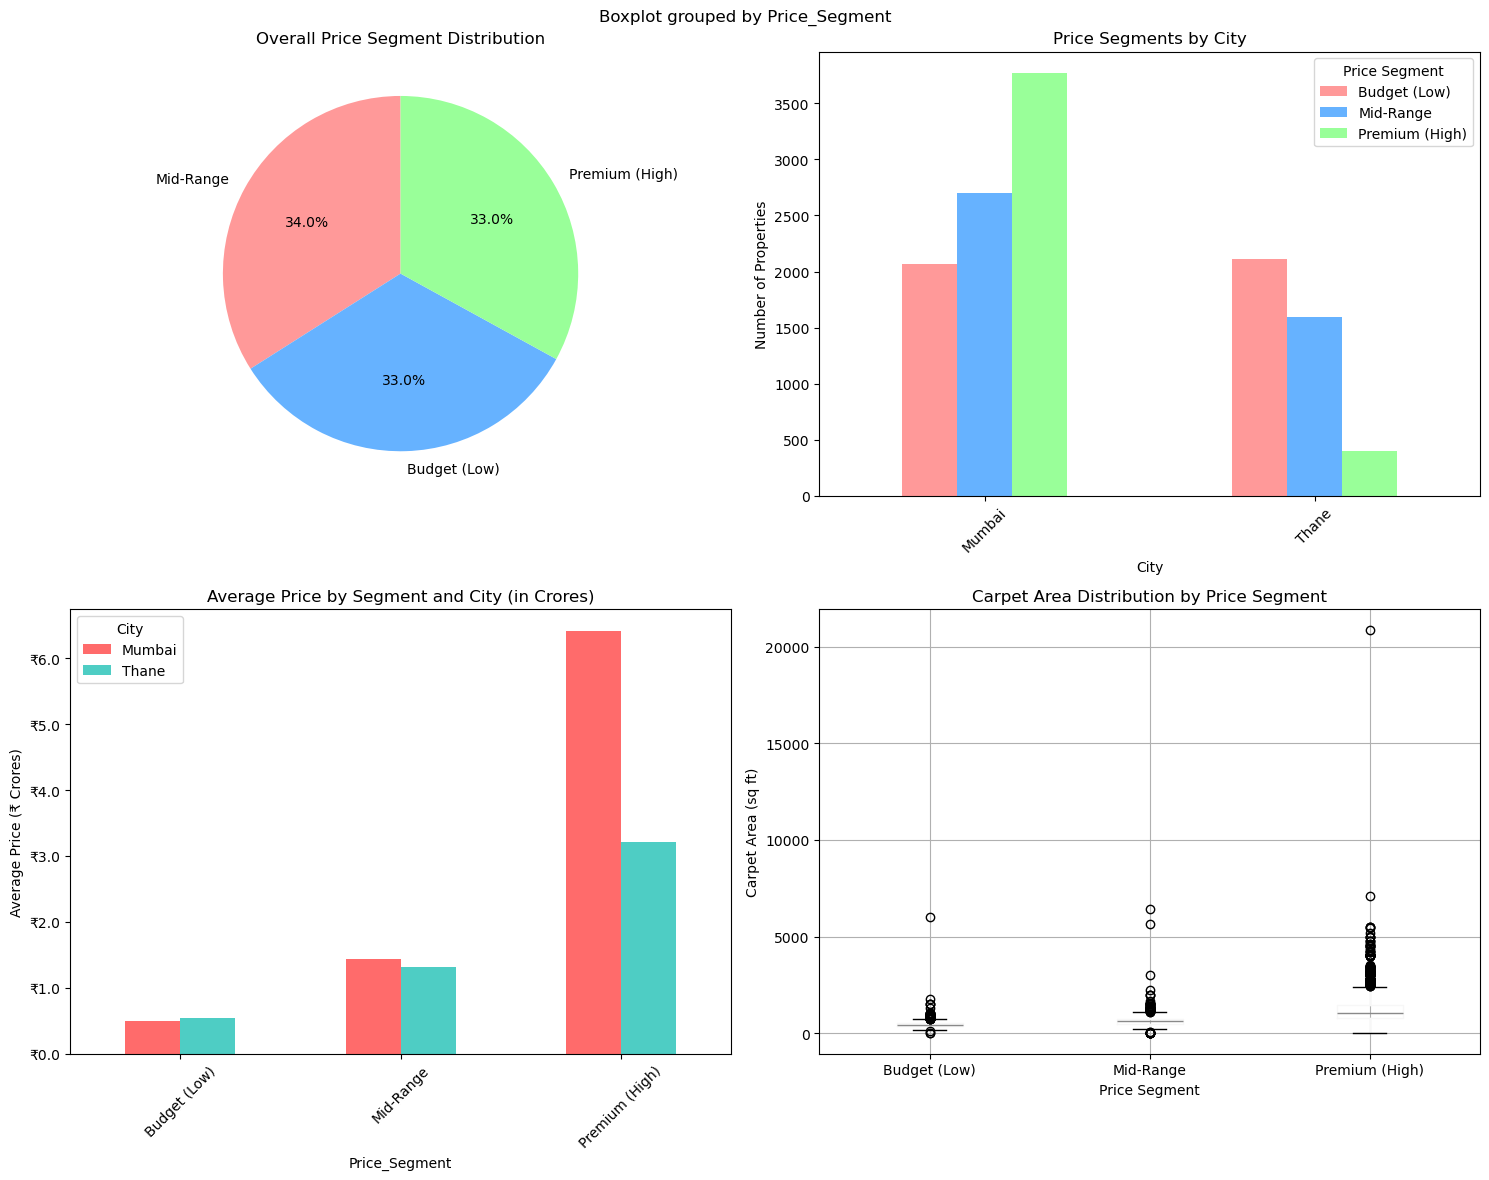


MARKET SUMMARY BY PRICE RANGE

📊 BUDGET (LOW) SEGMENT
----------------------------------------
• Total Properties: 4178
• Price Range: ₹1.0 - ₹88.0 Lakhs
• Average Price: ₹52.0 Lakhs
• Average Carpet Area: 470 sq ft
• City Distribution: {'Thane': 2114, 'Mumbai': 2064}
• Top Property Types: {'Apartment': 3897, 'Builder Floor Apartment': 145, 'Residential House': 121}
• Key Amenities Availability: {'Swimming Pool': '47%', 'Gymnasium': '49%', 'Club House': '49%', 'Security': '61%', 'Lift': '61%'}
💡 Investment Insight: Entry-level properties, good for first-time buyers and rental investments

📊 MID-RANGE SEGMENT
----------------------------------------
• Total Properties: 4302
• Price Range: ₹88.1 - ₹200.0 Lakhs
• Average Price: ₹139.1 Lakhs
• Average Carpet Area: 651 sq ft
• City Distribution: {'Mumbai': 2704, 'Thane': 1598}
• Top Property Types: {'Apartment': 4191, 'Residential House': 57, 'Builder Floor Apartment': 38}
• Key Amenities Availability: {'Swimming Pool': '59%', 'Gymnasium':

In [5]:
# 1. Price Segmentation & Market Overview

print("1. PRICE SEGMENTATION & MARKET OVERVIEW")
print("="*50)

# Define price ranges based on data distribution
price_percentiles = df_filtered['Price_Clean'].quantile([0.33, 0.67]).values
low_threshold = price_percentiles[0]
high_threshold = price_percentiles[1]

# Create price segments
def categorize_price(price):
    if price <= low_threshold:
        return 'Budget (Low)'
    elif price <= high_threshold:
        return 'Mid-Range'
    else:
        return 'Premium (High)'

df_filtered['Price_Segment'] = df_filtered['Price_Clean'].apply(categorize_price)

print(f"Price Segment Thresholds:")
print(f"Budget: ≤ ₹{low_threshold/100000:.1f} Lakhs")
print(f"Mid-Range: ₹{low_threshold/100000:.1f} - ₹{high_threshold/100000:.1f} Lakhs")
print(f"Premium: > ₹{high_threshold/100000:.1f} Lakhs")

# Analyze distribution across cities
price_city_analysis = df_filtered.groupby(['Price_Segment', 'City']).agg({
    'Price_Clean': ['count', 'mean'],
    'Carpet_Area_Clean': 'mean',
    'Type of Property': lambda x: x.mode()[0] if not x.empty else 'Unknown'
}).round(2)

price_city_analysis.columns = ['Count', 'Avg_Price', 'Avg_Carpet_Area', 'Common_Property_Type']

print("\nPrice Segment Distribution by City:")
print(price_city_analysis)

# Visualize price segmentation
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# Plot 1: Price segment distribution
segment_counts = df_filtered['Price_Segment'].value_counts()
colors = ['#FF9999', '#66B2FF', '#99FF99']
wedges, texts, autotexts = ax1.pie(segment_counts.values, labels=segment_counts.index, 
                                  autopct='%1.1f%%', colors=colors, startangle=90)
ax1.set_title('Overall Price Segment Distribution')

# Plot 2: City-wise price segments
pd.crosstab(df_filtered['City'], df_filtered['Price_Segment']).plot(kind='bar', ax=ax2, color=colors)
ax2.set_title('Price Segments by City')
ax2.set_xlabel('City')
ax2.set_ylabel('Number of Properties')
ax2.legend(title='Price Segment')
ax2.tick_params(axis='x', rotation=45)

# Plot 3: Average price by segment and city
price_segment_city = df_filtered.groupby(['Price_Segment', 'City'])['Price_Clean'].mean().unstack()
price_segment_city.plot(kind='bar', ax=ax3, color=['#FF6B6B', '#4ECDC4'])
ax3.set_title('Average Price by Segment and City (in Crores)')
ax3.set_ylabel('Average Price (₹ Crores)')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₹{x/10000000:.1f}'))
ax3.tick_params(axis='x', rotation=45)

# Plot 4: Carpet area by price segment
df_filtered.boxplot(column='Carpet_Area_Clean', by='Price_Segment', ax=ax4)
ax4.set_title('Carpet Area Distribution by Price Segment')
ax4.set_xlabel('Price Segment')
ax4.set_ylabel('Carpet Area (sq ft)')

plt.tight_layout()
plt.show()

# Market Summary for each price range
print("\n" + "="*60)
print("MARKET SUMMARY BY PRICE RANGE")
print("="*60)

for segment in ['Budget (Low)', 'Mid-Range', 'Premium (High)']:
    segment_data = df_filtered[df_filtered['Price_Segment'] == segment]
    
    print(f"\n📊 {segment.upper()} SEGMENT")
    print("-" * 40)
    print(f"• Total Properties: {len(segment_data)}")
    print(f"• Price Range: ₹{segment_data['Price_Clean'].min()/100000:.1f} - ₹{segment_data['Price_Clean'].max()/100000:.1f} Lakhs")
    print(f"• Average Price: ₹{segment_data['Price_Clean'].mean()/100000:.1f} Lakhs")
    print(f"• Average Carpet Area: {segment_data['Carpet_Area_Clean'].mean():.0f} sq ft")
    
    # City distribution
    city_dist = segment_data['City'].value_counts()
    print(f"• City Distribution: {dict(city_dist)}")
    
    # Property type distribution
    prop_type_dist = segment_data['Type of Property'].value_counts().head(3)
    print(f"• Top Property Types: {dict(prop_type_dist)}")
    
    # Key amenities analysis
    amenity_cols = ['Swimming Pool', 'Gymnasium', 'Club House', 'Security', 'Lift']
    amenities = {}
    for amenity in amenity_cols:
        if amenity in segment_data.columns:
            amenities[amenity] = f"{segment_data[amenity].sum()/len(segment_data)*100:.0f}%"
    print(f"• Key Amenities Availability: {amenities}")
    
    # Investment insight
    if segment == 'Budget (Low)':
        print("💡 Investment Insight: Entry-level properties, good for first-time buyers and rental investments")
    elif segment == 'Mid-Range':
        print("💡 Investment Insight: Balanced option with good amenities, suitable for families and steady appreciation")
    else:
        print("💡 Investment Insight: Premium properties with luxury amenities, high appreciation potential")



2. CITY-LEVEL COMPARATIVE ANALYSIS (MUMBAI vs THANE)
Mumbai Properties: 8542
Thane Properties: 4113

Overall City Comparison:
                 Metric  Mumbai   Thane Difference
       Total Properties  8542.0  4113.0     4429.0
    Avg Price (₹ Lakhs)   339.5   108.3      231.2
 Median Price (₹ Lakhs)   180.0    85.0       95.0
Avg Carpet Area (sq ft)   875.6   685.3      190.3
Avg Price per sq ft (₹) 28393.7 12436.9    15956.8

PROPERTY TYPE ANALYSIS


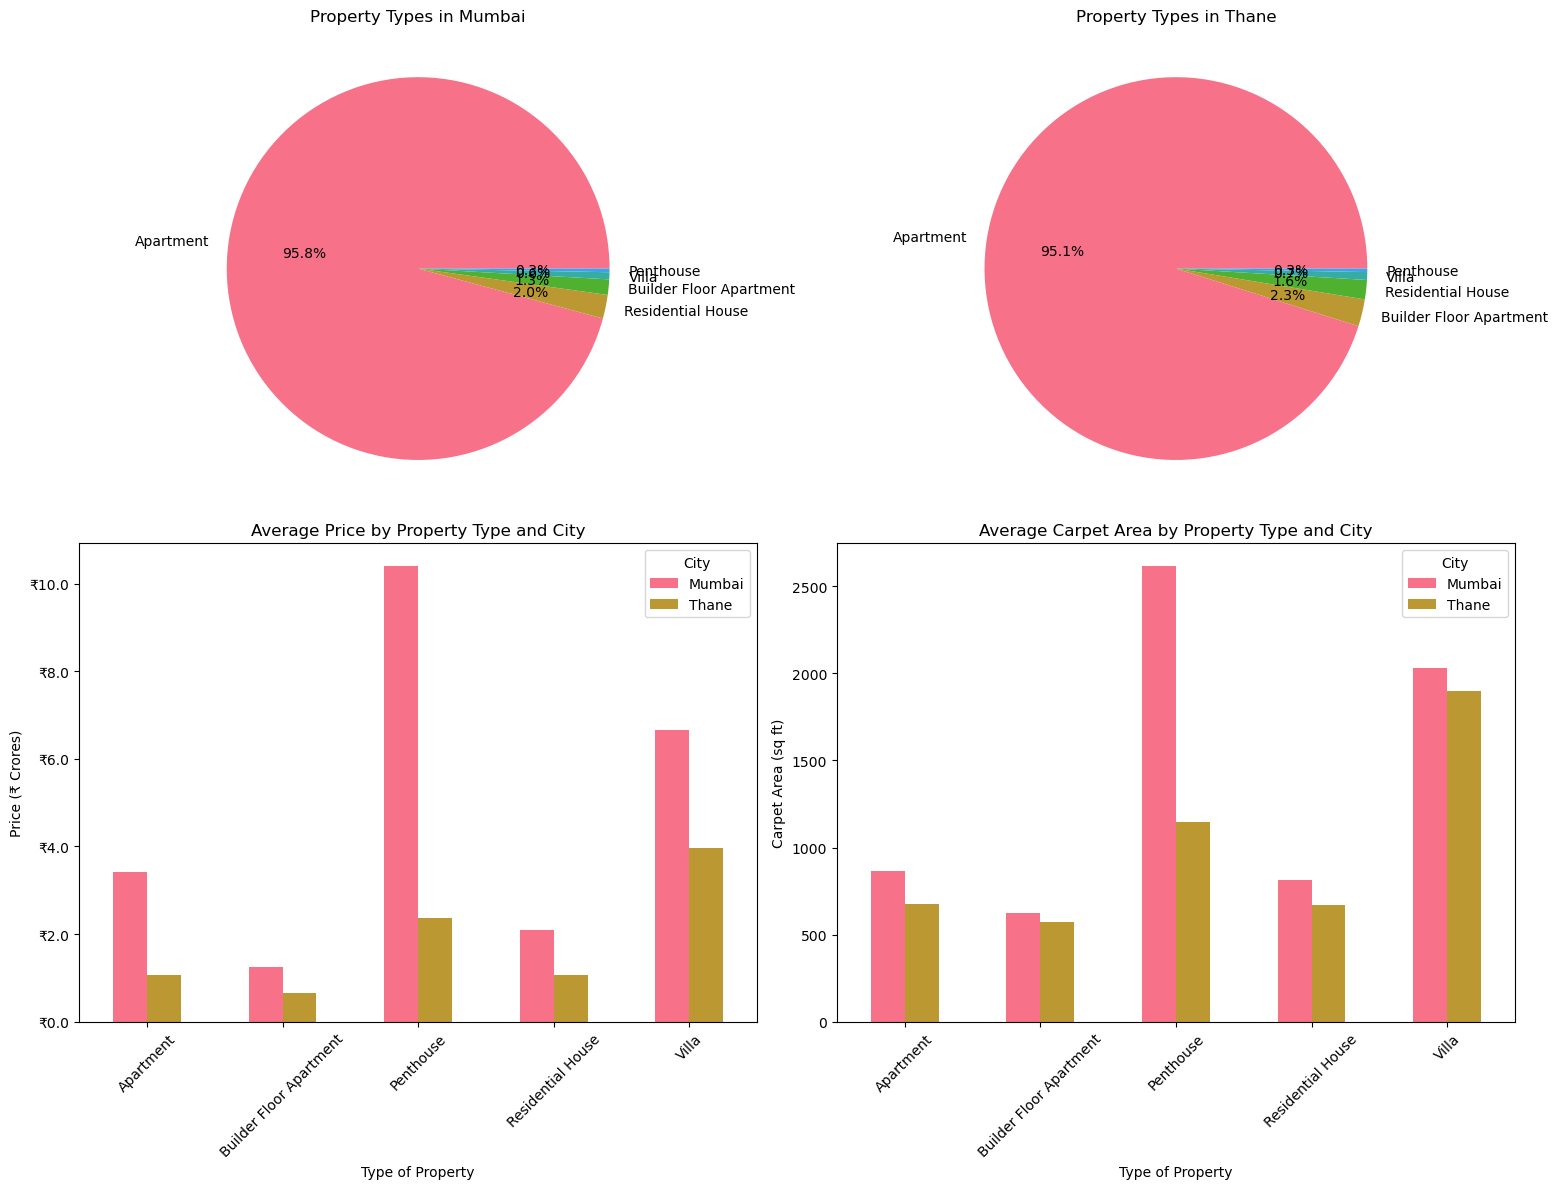


RESIDENTIAL vs COMMERCIAL ANALYSIS

Residential vs Commercial Analysis by City:
                    Count    Avg_Price  Median_Price  Avg_Carpet_Area  \
City   Segment                                                          
Mumbai Commercial     306  24875094.17     8250000.0          1032.79   
       Residential   8189  34289622.73    18200000.0           871.92   
Thane  Commercial     173   9260988.43     6500000.0           693.50   
       Residential   3903  10899340.99     8500000.0           685.04   

                    Avg_Price_per_sqft  
City   Segment                          
Mumbai Commercial             22428.39  
       Residential            28616.69  
Thane  Commercial             10894.28  
       Residential            12505.26  

BHK CONFIGURATION ANALYSIS (RESIDENTIAL)

BHK Analysis by City:
                         Count  Avg_Price_Lakhs  Avg_Carpet_Area  \
City   Bedroom_Category                                            
Mumbai 1 BHK              2556   

In [6]:
# 2. City-Level Comparative Analysis (Mumbai vs Thane)

print("\n\n2. CITY-LEVEL COMPARATIVE ANALYSIS (MUMBAI vs THANE)")
print("="*60)

# Separate data for Mumbai and Thane
mumbai_data = df_filtered[df_filtered['City'] == 'Mumbai']
thane_data = df_filtered[df_filtered['City'] == 'Thane']

print(f"Mumbai Properties: {len(mumbai_data)}")
print(f"Thane Properties: {len(thane_data)}")

# Comparative Analysis Function
def city_comparison(city1_data, city2_data, city1_name, city2_name):
    comparison_data = []
    
    metrics = [
        ('Total Properties', len(city1_data), len(city2_data)),
        ('Avg Price (₹ Lakhs)', city1_data['Price_Clean'].mean()/100000, city2_data['Price_Clean'].mean()/100000),
        ('Median Price (₹ Lakhs)', city1_data['Price_Clean'].median()/100000, city2_data['Price_Clean'].median()/100000),
        ('Avg Carpet Area (sq ft)', city1_data['Carpet_Area_Clean'].mean(), city2_data['Carpet_Area_Clean'].mean()),
        ('Avg Price per sq ft (₹)', city1_data['sqft_Price_Clean'].mean(), city2_data['sqft_Price_Clean'].mean())
    ]
    
    for metric, val1, val2 in metrics:
        comparison_data.append({
            'Metric': metric,
            city1_name: f"{val1:.1f}" if pd.notna(val1) else "N/A",
            city2_name: f"{val2:.1f}" if pd.notna(val2) else "N/A",
            'Difference': f"{val1-val2:.1f}" if pd.notna(val1) and pd.notna(val2) else "N/A"
        })
    
    return pd.DataFrame(comparison_data)

# Overall comparison
comparison_df = city_comparison(mumbai_data, thane_data, 'Mumbai', 'Thane')
print("\nOverall City Comparison:")
print(comparison_df.to_string(index=False))

# Property Type Analysis
print("\n" + "="*40)
print("PROPERTY TYPE ANALYSIS")
print("="*40)

# Create visualization for property types
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Property type distribution in Mumbai
if not mumbai_data.empty:
    mumbai_prop_types = mumbai_data['Type of Property'].value_counts().head(5)
    mumbai_prop_types.plot(kind='pie', ax=ax1, autopct='%1.1f%%')
    ax1.set_title('Property Types in Mumbai')
    ax1.set_ylabel('')

# Plot 2: Property type distribution in Thane
if not thane_data.empty:
    thane_prop_types = thane_data['Type of Property'].value_counts().head(5)
    thane_prop_types.plot(kind='pie', ax=ax2, autopct='%1.1f%%')
    ax2.set_title('Property Types in Thane')
    ax2.set_ylabel('')

# Plot 3: Price comparison by property type
prop_type_price = df_filtered.groupby(['City', 'Type of Property'])['Price_Clean'].mean().unstack(level=0)
if not prop_type_price.empty:
    prop_type_price.plot(kind='bar', ax=ax3)
    ax3.set_title('Average Price by Property Type and City')
    ax3.set_ylabel('Price (₹ Crores)')
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₹{x/10000000:.1f}'))
    ax3.tick_params(axis='x', rotation=45)

# Plot 4: Carpet area comparison
city_carpet_area = df_filtered.groupby(['City', 'Type of Property'])['Carpet_Area_Clean'].mean().unstack(level=0)
if not city_carpet_area.empty:
    city_carpet_area.plot(kind='bar', ax=ax4)
    ax4.set_title('Average Carpet Area by Property Type and City')
    ax4.set_ylabel('Carpet Area (sq ft)')
    ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Residential vs Commercial Analysis
print("\n" + "="*40)
print("RESIDENTIAL vs COMMERCIAL ANALYSIS")
print("="*40)

# Define residential and commercial properties
residential_types = ['Apartment', 'Villa', 'Independent House', 'Builder Floor']
df_filtered['Segment'] = df_filtered['Type of Property'].apply(
    lambda x: 'Residential' if x in residential_types else 'Commercial'
)

# Segment analysis by city
segment_analysis = df_filtered.groupby(['City', 'Segment']).agg({
    'Price_Clean': ['count', 'mean', 'median'],
    'Carpet_Area_Clean': 'mean',
    'sqft_Price_Clean': 'mean'
}).round(2)

segment_analysis.columns = ['Count', 'Avg_Price', 'Median_Price', 'Avg_Carpet_Area', 'Avg_Price_per_sqft']

print("\nResidential vs Commercial Analysis by City:")
print(segment_analysis)

# BHK Analysis for Residential Properties
residential_data = df_filtered[df_filtered['Segment'] == 'Residential']

print("\n" + "="*40)
print("BHK CONFIGURATION ANALYSIS (RESIDENTIAL)")
print("="*40)

bhk_analysis = residential_data.groupby(['City', 'Bedroom_Category']).agg({
    'Price_Clean': ['count', 'mean'],
    'Carpet_Area_Clean': 'mean',
    'sqft_Price_Clean': 'mean'
}).round(2)

bhk_analysis.columns = ['Count', 'Avg_Price_Lakhs', 'Avg_Carpet_Area', 'Avg_Price_per_sqft']
bhk_analysis['Avg_Price_Lakhs'] = bhk_analysis['Avg_Price_Lakhs'] / 100000

print("\nBHK Analysis by City:")
print(bhk_analysis)

# Investment Recommendations
print("\n" + "="*60)
print("🎯 INVESTMENT RECOMMENDATIONS: MUMBAI vs THANE")
print("="*60)

if not mumbai_data.empty and not thane_data.empty:
    mumbai_avg_price = mumbai_data['Price_Clean'].mean()
    thane_avg_price = thane_data['Price_Clean'].mean()
    mumbai_avg_sqft_price = mumbai_data['sqft_Price_Clean'].mean()
    thane_avg_sqft_price = thane_data['sqft_Price_Clean'].mean()
    
    print("\n🏢 MUMBAI:")
    print(f"• Higher average property prices (₹{mumbai_avg_price/100000:.1f} Lakhs vs ₹{thane_avg_price/100000:.1f} Lakhs)")
    print(f"• Premium per sq ft: ₹{mumbai_avg_sqft_price:.0f}")
    print("• Better for: High-end investments, commercial properties, luxury residential")
    print("• Risk-Return: Higher potential returns but higher entry cost")
    
    print("\n🏠 THANE:")
    print(f"• More affordable entry point (₹{thane_avg_price/100000:.1f} Lakhs average)")
    print(f"• Lower per sq ft cost: ₹{thane_avg_sqft_price:.0f}")
    print("• Better for: First-time buyers, larger carpet areas, family homes")
    print("• Risk-Return: Steady growth potential with lower investment requirement")
    
    if thane_avg_sqft_price < mumbai_avg_sqft_price:
        savings_percent = ((mumbai_avg_sqft_price - thane_avg_sqft_price) / mumbai_avg_sqft_price) * 100
        print(f"\n💰 COST ADVANTAGE: Thane offers {savings_percent:.1f}% savings in price per sq ft")
else:
    print("Insufficient data for detailed comparison")



3. LOCATION-BASED PREMIUM ANALYSIS
Total properties with location data: 12655

Location-based Analysis by City:
                           Count    Avg_Price  Median_Price  Avg_Carpet_Area  \
City   Location_Type                                                           
Mumbai Non-Prime Location   1646  16019011.61    12000000.0           657.00   
       Prime Location       6849  38259922.06    19900000.0           910.77   
Thane  Non-Prime Location   1560   9401047.96     8000000.0           637.90   
       Prime Location       2516  11715677.29     9000000.0           706.42   

                           Avg_Price_per_sqft  
City   Location_Type                           
Mumbai Non-Prime Location            20703.17  
       Prime Location                30242.99  
Thane  Non-Prime Location            12185.37  
       Prime Location                12592.83  

PRIME LOCATION PREMIUM ANALYSIS

🏙️ MUMBAI:
• Prime Location Avg Price: ₹382.6 Lakhs
• Non-Prime Location Avg Price:

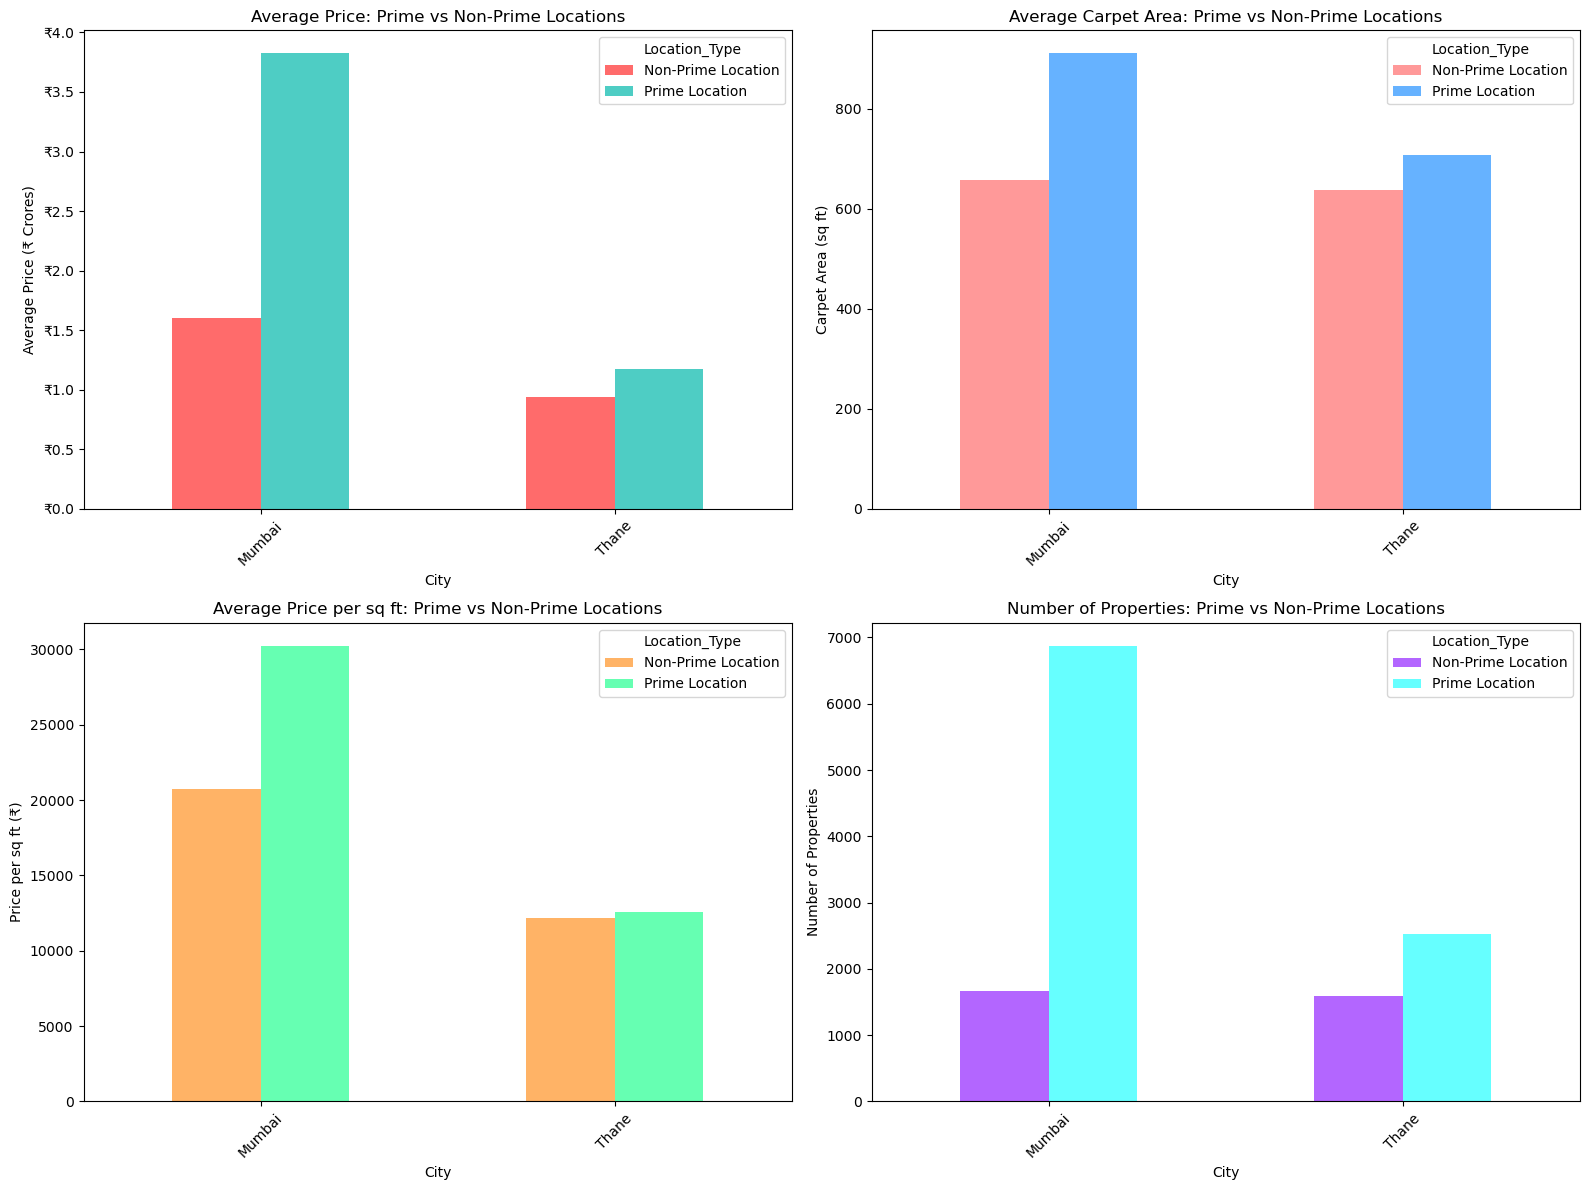


🏢 DETAILED AMENITIES ANALYSIS: PRIME vs NON-PRIME
Parking column sample values:
Parking
1 Covered            2902
1 Open               1575
2 Covered             925
1 Covered, 1 Open     524
3 Covered             186
Name: count, dtype: int64

Mumbai Parking: Prime 65.0%, Non-Prime 23.4%
Thane Parking: Prime 51.4%, Non-Prime 0.0%


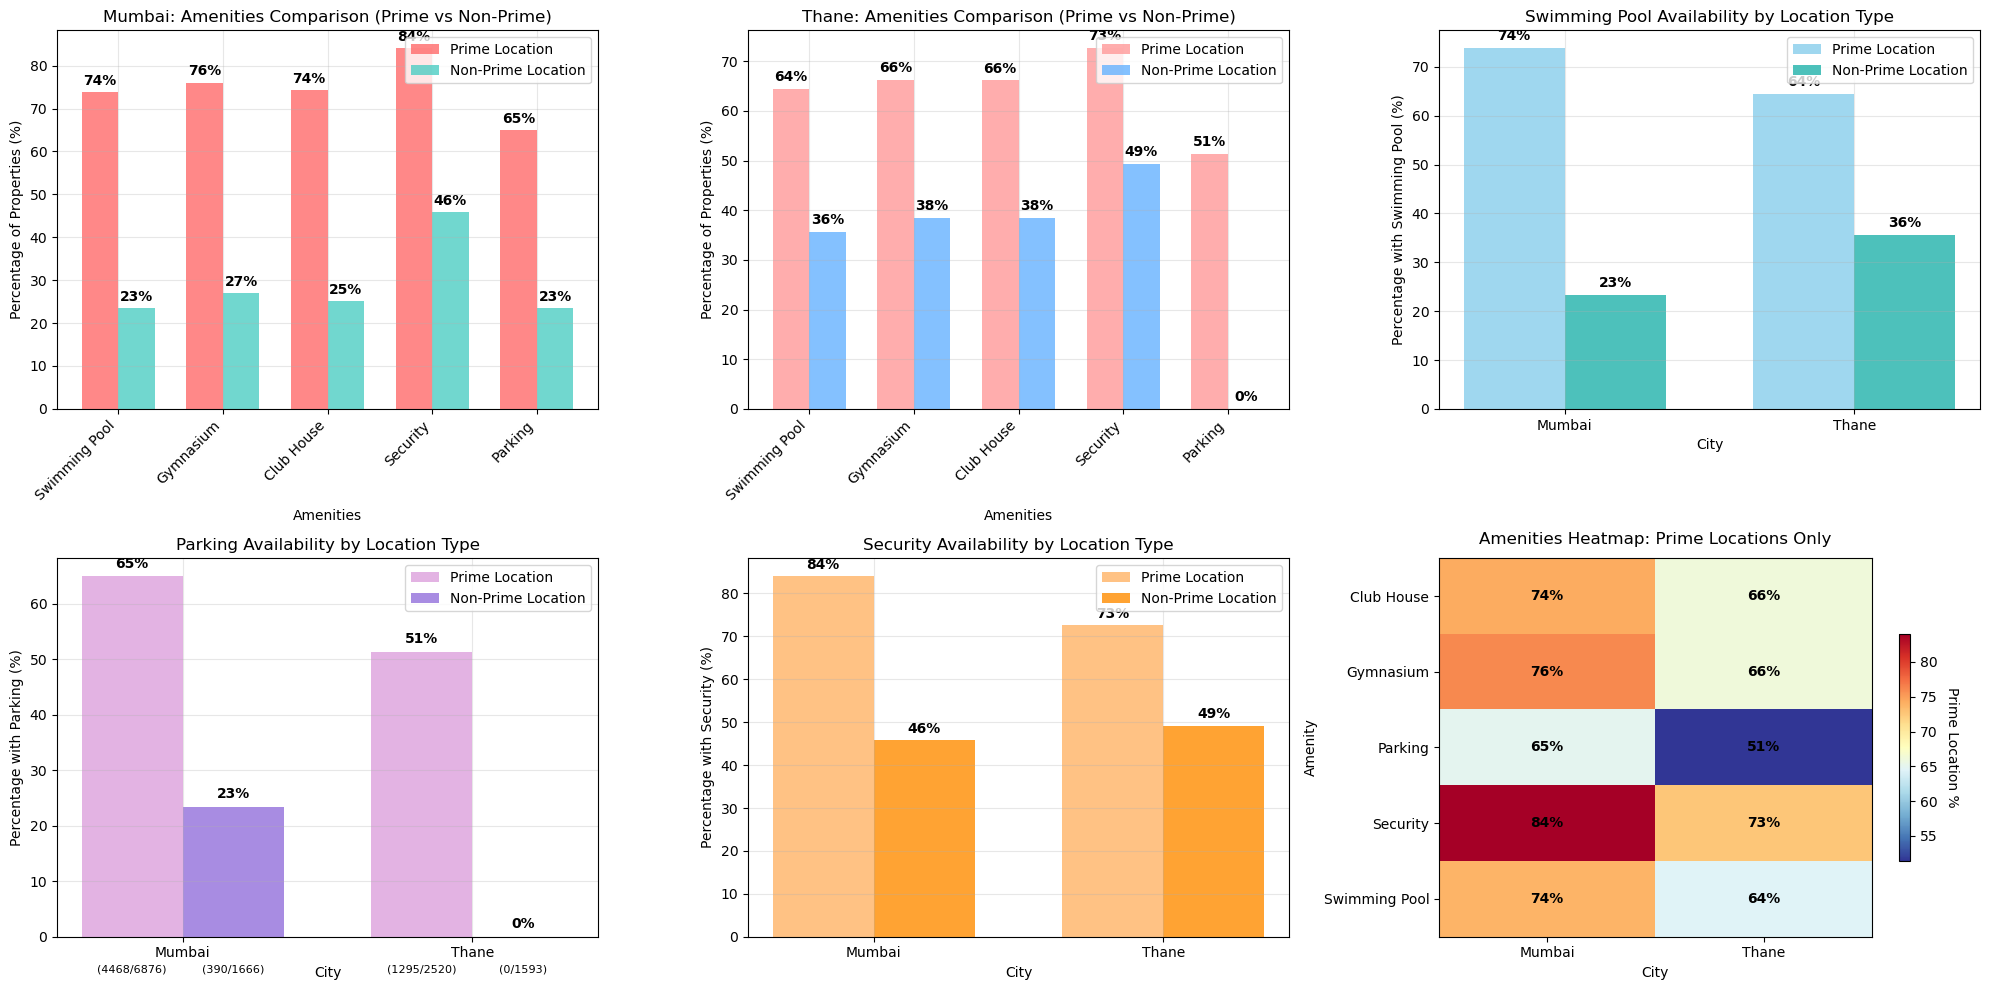


📊 AMENITIES ANALYSIS SUMMARY:

🏙️ MUMBAI:
--------------------
• Swimming Pool:
  - Prime: 74% (5075/6876)
  - Non-Prime: 23% (390/1666)
  - Difference: +50% ✅ Higher in Prime

• Gymnasium:
  - Prime: 76% (5228/6876)
  - Non-Prime: 27% (449/1666)
  - Difference: +49% ✅ Higher in Prime

• Club House:
  - Prime: 74% (5110/6876)
  - Non-Prime: 25% (419/1666)
  - Difference: +49% ✅ Higher in Prime

• Security:
  - Prime: 84% (5778/6876)
  - Non-Prime: 46% (763/1666)
  - Difference: +38% ✅ Higher in Prime

• Parking:
  - Prime: 65% (4468/6876)
  - Non-Prime: 23% (390/1666)
  - Difference: +42% ✅ Higher in Prime


🏙️ THANE:
--------------------
• Swimming Pool:
  - Prime: 64% (1623/2520)
  - Non-Prime: 36% (567/1593)
  - Difference: +29% ✅ Higher in Prime

• Gymnasium:
  - Prime: 66% (1667/2520)
  - Non-Prime: 38% (611/1593)
  - Difference: +28% ✅ Higher in Prime

• Club House:
  - Prime: 66% (1666/2520)
  - Non-Prime: 38% (613/1593)
  - Difference: +28% ✅ Higher in Prime

• Security:
  - P

In [7]:
# 3. Location-Based Premium Analysis

print("\n\n3. LOCATION-BASED PREMIUM ANALYSIS")
print("="*50)

# Analyze prime vs non-prime locations
if 'isPrimeLocationProperty' in df_filtered.columns:
    df_filtered['Location_Type'] = df_filtered['isPrimeLocationProperty'].map({
        'Y': 'Prime Location',
        'N': 'Non-Prime Location'
    })
    
    # Filter out null values
    location_data = df_filtered[df_filtered['Location_Type'].notna()]
    
    print(f"Total properties with location data: {len(location_data)}")
    
    # Analysis by city and location type
    location_analysis = location_data.groupby(['City', 'Location_Type']).agg({
        'Price_Clean': ['count', 'mean', 'median'],
        'Carpet_Area_Clean': 'mean',
        'sqft_Price_Clean': 'mean'
    }).round(2)
    
    location_analysis.columns = ['Count', 'Avg_Price', 'Median_Price', 'Avg_Carpet_Area', 'Avg_Price_per_sqft']
    
    print("\nLocation-based Analysis by City:")
    print(location_analysis)
    
    # Calculate premium analysis
    print("\n" + "="*40)
    print("PRIME LOCATION PREMIUM ANALYSIS")
    print("="*40)
    
    for city in ['Mumbai', 'Thane']:
        city_data = location_data[location_data['City'] == city]
        if len(city_data) > 0:
            prime_data = city_data[city_data['Location_Type'] == 'Prime Location']
            non_prime_data = city_data[city_data['Location_Type'] == 'Non-Prime Location']
            
            if len(prime_data) > 0 and len(non_prime_data) > 0:
                print(f"\n🏙️ {city.upper()}:")
                
                # Price premium
                prime_avg_price = prime_data['Price_Clean'].mean()
                non_prime_avg_price = non_prime_data['Price_Clean'].mean()
                price_premium = ((prime_avg_price - non_prime_avg_price) / non_prime_avg_price) * 100
                
                print(f"• Prime Location Avg Price: ₹{prime_avg_price/100000:.1f} Lakhs")
                print(f"• Non-Prime Location Avg Price: ₹{non_prime_avg_price/100000:.1f} Lakhs")
                print(f"• Price Premium: {price_premium:.1f}%")
                
                # Carpet area comparison
                prime_avg_area = prime_data['Carpet_Area_Clean'].mean()
                non_prime_avg_area = non_prime_data['Carpet_Area_Clean'].mean()
                
                if pd.notna(prime_avg_area) and pd.notna(non_prime_avg_area):
                    area_difference = prime_avg_area - non_prime_avg_area
                    print(f"• Prime Location Avg Area: {prime_avg_area:.0f} sq ft")
                    print(f"• Non-Prime Location Avg Area: {non_prime_avg_area:.0f} sq ft")
                    print(f"• Area Difference: {area_difference:.0f} sq ft")
                
                # Price per sq ft premium
                prime_sqft_price = prime_data['sqft_Price_Clean'].mean()
                non_prime_sqft_price = non_prime_data['sqft_Price_Clean'].mean()
                
                if pd.notna(prime_sqft_price) and pd.notna(non_prime_sqft_price):
                    sqft_premium = ((prime_sqft_price - non_prime_sqft_price) / non_prime_sqft_price) * 100
                    print(f"• Prime Location Price/sq ft: ₹{prime_sqft_price:.0f}")
                    print(f"• Non-Prime Location Price/sq ft: ₹{non_prime_sqft_price:.0f}")
                    print(f"• Price/sq ft Premium: {sqft_premium:.1f}%")
                
                # Amenities comparison with improved parsing
                amenity_cols = ['Swimming Pool', 'Gymnasium', 'Club House', 'Security', 'Parking']
                print(f"• Amenities Comparison:")
                for amenity in amenity_cols:
                    if amenity in prime_data.columns:
                        # Enhanced conversion handling multiple formats including 0/1, Y/N, Yes/No, and parking descriptive values
                        def convert_amenity(series):
                            # Convert to string first, then handle various formats
                            series_str = series.astype(str).str.strip().str.upper()
                            
                            # Special handling for Parking column
                            if amenity == 'Parking':
                                # For parking, any mention of covered/open parking means it exists
                                return series_str.apply(lambda x: 1 if ('COVERED' in str(x) or 'OPEN' in str(x)) and 'NAN' not in str(x) else 0)
                            
                            # Map various formats to 1/0
                            mapping = {
                                'Y': 1, 'YES': 1, '1': 1, '1.0': 1, 'TRUE': 1,
                                'N': 0, 'NO': 0, '0': 0, '0.0': 0, 'FALSE': 0, 'NAN': 0, 'NONE': 0
                            }
                            return series_str.map(mapping).fillna(0).astype(int)
                        
                        prime_amenity_values = convert_amenity(prime_data[amenity])
                        non_prime_amenity_values = convert_amenity(non_prime_data[amenity])
                        
                        prime_amenity_pct = (prime_amenity_values.sum() / len(prime_data)) * 100
                        non_prime_amenity_pct = (non_prime_amenity_values.sum() / len(non_prime_data)) * 100
                        print(f"  - {amenity}: Prime {prime_amenity_pct:.0f}% vs Non-Prime {non_prime_amenity_pct:.0f}%")
    
    # Visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # Plot 1: Price comparison by location type
    location_price = location_data.groupby(['City', 'Location_Type'])['Price_Clean'].mean().unstack()
    if not location_price.empty:
        location_price.plot(kind='bar', ax=ax1, color=['#FF6B6B', '#4ECDC4'])
        ax1.set_title('Average Price: Prime vs Non-Prime Locations')
        ax1.set_ylabel('Average Price (₹ Crores)')
        ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₹{x/10000000:.1f}'))
        ax1.tick_params(axis='x', rotation=45)
    
    # Plot 2: Carpet area comparison
    location_area = location_data.groupby(['City', 'Location_Type'])['Carpet_Area_Clean'].mean().unstack()
    if not location_area.empty:
        location_area.plot(kind='bar', ax=ax2, color=['#FF9999', '#66B2FF'])
        ax2.set_title('Average Carpet Area: Prime vs Non-Prime Locations')
        ax2.set_ylabel('Carpet Area (sq ft)')
        ax2.tick_params(axis='x', rotation=45)
    
    # Plot 3: Price per sq ft comparison
    location_sqft_price = location_data.groupby(['City', 'Location_Type'])['sqft_Price_Clean'].mean().unstack()
    if not location_sqft_price.empty:
        location_sqft_price.plot(kind='bar', ax=ax3, color=['#FFB366', '#66FFB2'])
        ax3.set_title('Average Price per sq ft: Prime vs Non-Prime Locations')
        ax3.set_ylabel('Price per sq ft (₹)')
        ax3.tick_params(axis='x', rotation=45)
    
    # Plot 4: Distribution of location types
    location_counts = location_data.groupby(['City', 'Location_Type']).size().unstack()
    if not location_counts.empty:
        location_counts.plot(kind='bar', ax=ax4, color=['#B366FF', '#66FFFF'])
        ax4.set_title('Number of Properties: Prime vs Non-Prime Locations')
        ax4.set_ylabel('Number of Properties')
        ax4.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
    
    # COMPREHENSIVE AMENITIES COMPARISON GRAPHS
    print("\n" + "="*60)
    print("🏢 DETAILED AMENITIES ANALYSIS: PRIME vs NON-PRIME")
    print("="*60)
    
    # Enhanced amenity conversion function
    def convert_amenity_enhanced(series):
        """Convert amenity data to binary (0/1) handling multiple formats"""
        series_str = series.astype(str).str.strip().str.upper()
        
        # Check if this looks like parking data (contains "COVERED" or "OPEN")
        sample_values = series_str.dropna().head(5).tolist()
        is_parking_data = any('COVERED' in str(val) or 'OPEN' in str(val) for val in sample_values)
        
        if is_parking_data:
            # For parking, any mention of covered/open parking means it exists
            return series_str.apply(lambda x: 1 if ('COVERED' in str(x) or 'OPEN' in str(x)) and 'NAN' not in str(x) else 0)
        
        # Standard mapping for other amenities
        mapping = {
            'Y': 1, 'YES': 1, '1': 1, '1.0': 1, 'TRUE': 1,
            'N': 0, 'NO': 0, '0': 0, '0.0': 0, 'FALSE': 0, 'NAN': 0, 'NONE': 0
        }
        return series_str.map(mapping).fillna(0).astype(int)
    
    # Create amenities comparison data
    amenity_cols = ['Swimming Pool', 'Gymnasium', 'Club House', 'Security', 'Parking']
    amenities_data = []
    
    # Debug: Check parking data
    if 'Parking' in location_data.columns:
        print(f"Parking column sample values:")
        print(location_data['Parking'].value_counts().head(5))
        print()
    
    for city in ['Mumbai', 'Thane']:
        city_data = location_data[location_data['City'] == city]
        if len(city_data) > 0:
            prime_data = city_data[city_data['Location_Type'] == 'Prime Location']
            non_prime_data = city_data[city_data['Location_Type'] == 'Non-Prime Location']
            
            if len(prime_data) > 0 and len(non_prime_data) > 0:
                for amenity in amenity_cols:
                    if amenity in city_data.columns:
                        prime_amenity_pct = (convert_amenity_enhanced(prime_data[amenity]).sum() / len(prime_data)) * 100
                        non_prime_amenity_pct = (convert_amenity_enhanced(non_prime_data[amenity]).sum() / len(non_prime_data)) * 100
                        
                        amenities_data.append({
                            'City': city,
                            'Amenity': amenity,
                            'Prime_Percentage': prime_amenity_pct,
                            'Non_Prime_Percentage': non_prime_amenity_pct,
                            'Prime_Count': convert_amenity_enhanced(prime_data[amenity]).sum(),
                            'Non_Prime_Count': convert_amenity_enhanced(non_prime_data[amenity]).sum(),
                            'Prime_Total': len(prime_data),
                            'Non_Prime_Total': len(non_prime_data)
                        })
                        
                        # Debug print for parking
                        if amenity == 'Parking':
                            print(f"{city} {amenity}: Prime {prime_amenity_pct:.1f}%, Non-Prime {non_prime_amenity_pct:.1f}%")
    
    amenities_df = pd.DataFrame(amenities_data)
    
    if not amenities_df.empty:
        # Create comprehensive amenities visualization with optimized layout
        fig, axes = plt.subplots(2, 3, figsize=(20, 10))
        axes = axes.flatten()
        
        # Adjust subplot spacing to reduce white space
        plt.subplots_adjust(hspace=0.3, wspace=0.3, top=0.95, bottom=0.1, left=0.05, right=0.95)
        
        # Plot 1: Overall Amenities Comparison - Mumbai
        mumbai_amenities = amenities_df[amenities_df['City'] == 'Mumbai']
        if not mumbai_amenities.empty:
            x = range(len(mumbai_amenities))
            width = 0.35
            
            axes[0].bar([i - width/2 for i in x], mumbai_amenities['Prime_Percentage'], 
                       width, label='Prime Location', color='#FF6B6B', alpha=0.8)
            axes[0].bar([i + width/2 for i in x], mumbai_amenities['Non_Prime_Percentage'], 
                       width, label='Non-Prime Location', color='#4ECDC4', alpha=0.8)
            
            axes[0].set_xlabel('Amenities')
            axes[0].set_ylabel('Percentage of Properties (%)')
            axes[0].set_title('Mumbai: Amenities Comparison (Prime vs Non-Prime)')
            axes[0].set_xticks(x)
            axes[0].set_xticklabels(mumbai_amenities['Amenity'], rotation=45, ha='right')
            axes[0].legend()
            axes[0].grid(True, alpha=0.3)
            
            # Add value labels
            for i, (prime_pct, non_prime_pct) in enumerate(zip(mumbai_amenities['Prime_Percentage'], 
                                                             mumbai_amenities['Non_Prime_Percentage'])):
                axes[0].text(i - width/2, prime_pct + 1, f'{prime_pct:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
                axes[0].text(i + width/2, non_prime_pct + 1, f'{non_prime_pct:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
        
        # Plot 2: Overall Amenities Comparison - Thane
        thane_amenities = amenities_df[amenities_df['City'] == 'Thane']
        if not thane_amenities.empty:
            x = range(len(thane_amenities))
            width = 0.35
            
            axes[1].bar([i - width/2 for i in x], thane_amenities['Prime_Percentage'], 
                       width, label='Prime Location', color='#FF9999', alpha=0.8)
            axes[1].bar([i + width/2 for i in x], thane_amenities['Non_Prime_Percentage'], 
                       width, label='Non-Prime Location', color='#66B2FF', alpha=0.8)
            
            axes[1].set_xlabel('Amenities')
            axes[1].set_ylabel('Percentage of Properties (%)')
            axes[1].set_title('Thane: Amenities Comparison (Prime vs Non-Prime)')
            axes[1].set_xticks(x)
            axes[1].set_xticklabels(thane_amenities['Amenity'], rotation=45, ha='right')
            axes[1].legend()
            axes[1].grid(True, alpha=0.3)
            
            # Add value labels
            for i, (prime_pct, non_prime_pct) in enumerate(zip(thane_amenities['Prime_Percentage'], 
                                                             thane_amenities['Non_Prime_Percentage'])):
                axes[1].text(i - width/2, prime_pct + 1, f'{prime_pct:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
                axes[1].text(i + width/2, non_prime_pct + 1, f'{non_prime_pct:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
        
        # Plot 3: Swimming Pool Analysis
        pool_data = amenities_df[amenities_df['Amenity'] == 'Swimming Pool']
        if not pool_data.empty:
            cities = pool_data['City']
            prime_values = pool_data['Prime_Percentage']
            non_prime_values = pool_data['Non_Prime_Percentage']
            
            x = range(len(cities))
            width = 0.35
            
            axes[2].bar([i - width/2 for i in x], prime_values, width, 
                       label='Prime Location', color='#87CEEB', alpha=0.8)
            axes[2].bar([i + width/2 for i in x], non_prime_values, width, 
                       label='Non-Prime Location', color='#20B2AA', alpha=0.8)
            
            axes[2].set_xlabel('City')
            axes[2].set_ylabel('Percentage with Swimming Pool (%)')
            axes[2].set_title('Swimming Pool Availability by Location Type')
            axes[2].set_xticks(x)
            axes[2].set_xticklabels(cities)
            axes[2].legend()
            axes[2].grid(True, alpha=0.3)
            
            # Add value labels
            for i, (prime_val, non_prime_val) in enumerate(zip(prime_values, non_prime_values)):
                axes[2].text(i - width/2, prime_val + 1, f'{prime_val:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
                axes[2].text(i + width/2, non_prime_val + 1, f'{non_prime_val:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
        
        # Plot 4: Parking Analysis (Fixed)
        parking_data = amenities_df[amenities_df['Amenity'] == 'Parking']
        if not parking_data.empty:
            cities = parking_data['City']
            prime_values = parking_data['Prime_Percentage']
            non_prime_values = parking_data['Non_Prime_Percentage']
            
            x = range(len(cities))
            width = 0.35
            
            axes[3].bar([i - width/2 for i in x], prime_values, width, 
                       label='Prime Location', color='#DDA0DD', alpha=0.8)
            axes[3].bar([i + width/2 for i in x], non_prime_values, width, 
                       label='Non-Prime Location', color='#9370DB', alpha=0.8)
            
            axes[3].set_xlabel('City')
            axes[3].set_ylabel('Percentage with Parking (%)')
            axes[3].set_title('Parking Availability by Location Type')
            axes[3].set_xticks(x)
            axes[3].set_xticklabels(cities)
            axes[3].legend()
            axes[3].grid(True, alpha=0.3)
            
            # Add value labels and detailed info
            for i, (city, prime_val, non_prime_val, prime_count, prime_total, non_prime_count, non_prime_total) in enumerate(
                zip(cities, prime_values, non_prime_values, 
                    parking_data['Prime_Count'], parking_data['Prime_Total'],
                    parking_data['Non_Prime_Count'], parking_data['Non_Prime_Total'])):
                axes[3].text(i - width/2, prime_val + 1, f'{prime_val:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
                axes[3].text(i + width/2, non_prime_val + 1, f'{non_prime_val:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
                
                # Add count info below
                axes[3].text(i - width/2, -5, f'({prime_count}/{prime_total})', 
                           ha='center', va='top', fontsize=8)
                axes[3].text(i + width/2, -5, f'({non_prime_count}/{non_prime_total})', 
                           ha='center', va='top', fontsize=8)
        
        # Plot 5: Security Analysis
        security_data = amenities_df[amenities_df['Amenity'] == 'Security']
        if not security_data.empty:
            cities = security_data['City']
            prime_values = security_data['Prime_Percentage']
            non_prime_values = security_data['Non_Prime_Percentage']
            
            x = range(len(cities))
            width = 0.35
            
            axes[4].bar([i - width/2 for i in x], prime_values, width, 
                       label='Prime Location', color='#FFB366', alpha=0.8)
            axes[4].bar([i + width/2 for i in x], non_prime_values, width, 
                       label='Non-Prime Location', color='#FF8C00', alpha=0.8)
            
            axes[4].set_xlabel('City')
            axes[4].set_ylabel('Percentage with Security (%)')
            axes[4].set_title('Security Availability by Location Type')
            axes[4].set_xticks(x)
            axes[4].set_xticklabels(cities)
            axes[4].legend()
            axes[4].grid(True, alpha=0.3)
            
            # Add value labels
            for i, (prime_val, non_prime_val) in enumerate(zip(prime_values, non_prime_values)):
                axes[4].text(i - width/2, prime_val + 1, f'{prime_val:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
                axes[4].text(i + width/2, non_prime_val + 1, f'{non_prime_val:.0f}%', 
                           ha='center', va='bottom', fontweight='bold')
        
        # Plot 6: Amenities Summary Heatmap - Compact design
        pivot_data = amenities_df.pivot_table(
            values='Prime_Percentage', 
            index='Amenity', 
            columns='City', 
            fill_value=0
        )
        
        if not pivot_data.empty:
            # Create a more compact heatmap
            im = axes[5].imshow(pivot_data.values, cmap='RdYlBu_r', aspect='auto')
            
            # Set ticks and labels
            axes[5].set_xticks(range(len(pivot_data.columns)))
            axes[5].set_yticks(range(len(pivot_data.index)))
            axes[5].set_xticklabels(pivot_data.columns)
            axes[5].set_yticklabels(pivot_data.index)
            
            # Add text annotations
            for i in range(len(pivot_data.index)):
                for j in range(len(pivot_data.columns)):
                    axes[5].text(j, i, f'{pivot_data.iloc[i, j]:.0f}%', 
                               ha='center', va='center', fontweight='bold', fontsize=10)
            
            axes[5].set_title('Amenities Heatmap: Prime Locations Only', pad=10, fontsize=12)
            axes[5].set_xlabel('City', fontsize=10)
            axes[5].set_ylabel('Amenity', fontsize=10)
            
            # Add colorbar
            cbar = plt.colorbar(im, ax=axes[5], shrink=0.6)
            cbar.set_label('Prime Location %', rotation=270, labelpad=15)
        
        # Apply tight layout to minimize white space
        plt.tight_layout()
        plt.show()
        
        # Print detailed amenities summary
        print("\n📊 AMENITIES ANALYSIS SUMMARY:")
        print("="*50)
        
        for city in ['Mumbai', 'Thane']:
            city_amenities = amenities_df[amenities_df['City'] == city]
            if not city_amenities.empty:
                print(f"\n🏙️ {city.upper()}:")
                print("-" * 20)
                
                for _, row in city_amenities.iterrows():
                    amenity = row['Amenity']
                    prime_pct = row['Prime_Percentage']
                    non_prime_pct = row['Non_Prime_Percentage']
                    difference = prime_pct - non_prime_pct
                    
                    status = "✅ Higher in Prime" if difference > 5 else "⚠️ Similar" if abs(difference) <= 5 else "❌ Higher in Non-Prime"
                    
                    print(f"• {amenity}:")
                    print(f"  - Prime: {prime_pct:.0f}% ({row['Prime_Count']}/{row['Prime_Total']})")
                    print(f"  - Non-Prime: {non_prime_pct:.0f}% ({row['Non_Prime_Count']}/{row['Non_Prime_Total']})")
                    print(f"  - Difference: {difference:+.0f}% {status}")
                    print()
    
    else:
        print("❌ No amenities data available for comparison")
    
    # Investment Justification Analysis
    print("\n" + "="*60)
    print("🎯 LOCATION PREMIUM JUSTIFICATION ANALYSIS")
    print("="*60)
    
    for city in ['Mumbai', 'Thane']:
        city_data = location_data[location_data['City'] == city]
        if len(city_data) > 0:
            prime_data = city_data[city_data['Location_Type'] == 'Prime Location']
            non_prime_data = city_data[city_data['Location_Type'] == 'Non-Prime Location']
            
            if len(prime_data) > 0 and len(non_prime_data) > 0:
                prime_avg_price = prime_data['Price_Clean'].mean()
                non_prime_avg_price = non_prime_data['Price_Clean'].mean()
                price_premium = ((prime_avg_price - non_prime_avg_price) / non_prime_avg_price) * 100
                
                prime_sqft_price = prime_data['sqft_Price_Clean'].mean()
                non_prime_sqft_price = non_prime_data['sqft_Price_Clean'].mean()
                
                print(f"\n🏙️ {city}:")
                
                # Determine if premium is justified
                if pd.notna(prime_sqft_price) and pd.notna(non_prime_sqft_price):
                    sqft_premium = ((prime_sqft_price - non_prime_sqft_price) / non_prime_sqft_price) * 100
                    
                    if sqft_premium > 50:
                        justification = "❌ HIGH PREMIUM - May not be justified"
                        recommendation = "Consider non-prime locations for better value"
                    elif sqft_premium > 25:
                        justification = "⚠️ MODERATE PREMIUM - Partially justified"
                        recommendation = "Evaluate based on specific amenities and location benefits"
                    else:
                        justification = "✅ REASONABLE PREMIUM - Well justified"
                        recommendation = "Prime locations offer good value for premium paid"
                    
                    print(f"• Premium Assessment: {justification}")
                    print(f"• Investment Recommendation: {recommendation}")
                    print(f"• Premium Percentage: {sqft_premium:.1f}% higher price per sq ft")

else:
    print("Prime location data not available for analysis")



4. VALUE-FOR-MONEY OPPORTUNITIES
Properties analyzed for value: 9580

TOP 10 VALUE-FOR-MONEY PROPERTIES

10. Nalasopara West, Mumbai
   Type: Apartment | 2 BHK
   Price: ₹39.8 Lakhs | Carpet Area: 550 sq ft
   Value Score: 13.8 sq ft per Lakh
   Developer: nan | Status: Ready to Move

9. Vasai East, Mumbai
   Type: Apartment | 1 BHK
   Price: ₹28.2 Lakhs | Carpet Area: 390 sq ft
   Value Score: 13.8 sq ft per Lakh
   Developer: Shripal Group | Status: Under Construction

8. Vasai East, Mumbai
   Type: Apartment | 1 BHK
   Price: ₹28.2 Lakhs | Carpet Area: 390 sq ft
   Value Score: 13.8 sq ft per Lakh
   Developer: Shripal Group | Status: Under Construction

7. Nalasopara West, Mumbai
   Type: Apartment | 1 BHK
   Price: ₹25.0 Lakhs | Carpet Area: 345 sq ft
   Value Score: 13.8 sq ft per Lakh
   Developer: nan | Status: Ready to Move

6. Nalasopara West, Mumbai
   Type: Apartment | 1 BHK
   Price: ₹29.0 Lakhs | Carpet Area: 400 sq ft
   Value Score: 13.8 sq ft per Lakh
   Developer: V

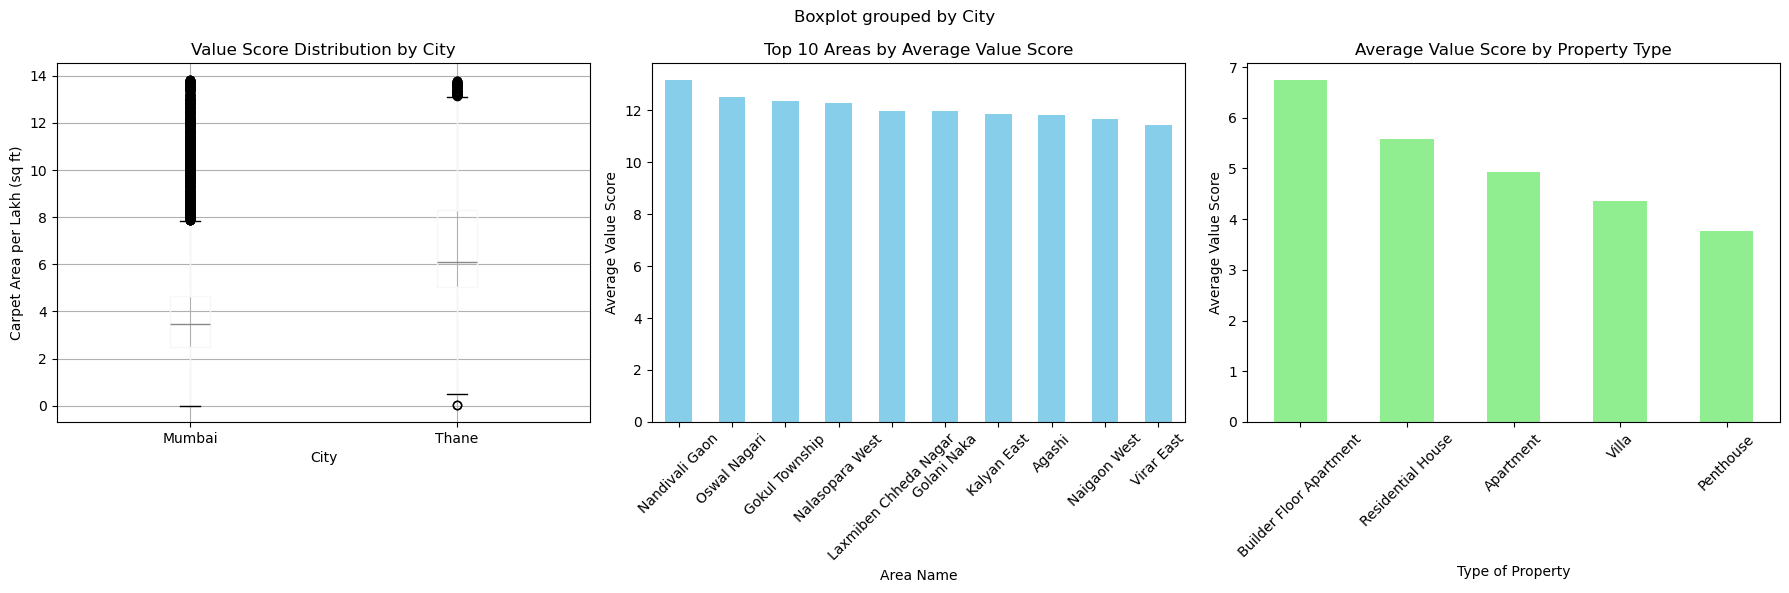


🎯 BEST VALUE OPPORTUNITIES BY CRITERIA

🏙️ TOP 3 VALUE PICKS IN MUMBAI:
1. Nalasopara West - Apartment
   💰 ₹39.8 Lakhs | 📐 550 sq ft
   📊 Value: 13.8 sq ft/Lakh | 🏗️ nan
2. Vasai East - Apartment
   💰 ₹28.2 Lakhs | 📐 390 sq ft
   📊 Value: 13.8 sq ft/Lakh | 🏗️ Shripal Group
3. Vasai East - Apartment
   💰 ₹28.2 Lakhs | 📐 390 sq ft
   📊 Value: 13.8 sq ft/Lakh | 🏗️ Shripal Group

🏙️ TOP 3 VALUE PICKS IN THANE:
1. Dombivli East - Apartment
   💰 ₹57.0 Lakhs | 📐 786 sq ft
   📊 Value: 13.8 sq ft/Lakh | 🏗️ nan
2. Dombivli East - Apartment
   💰 ₹37.0 Lakhs | 📐 510 sq ft
   📊 Value: 13.8 sq ft/Lakh | 🏗️ Lodha
3. Dombivli East - Apartment
   💰 ₹42.5 Lakhs | 📐 585 sq ft
   📊 Value: 13.8 sq ft/Lakh | 🏗️ Lodha

💡 BEST VALUE BY BUDGET RANGES:

Under ₹30 Lakhs:
  1. Vasai East, Mumbai - Apartment
     ₹28.2 Lakhs | 390 sq ft | Value: 13.8
  2. Vasai East, Mumbai - Apartment
     ₹28.2 Lakhs | 390 sq ft | Value: 13.8

₹30-60 Lakhs:
  1. Nalasopara West, Mumbai - Apartment
     ₹39.8 Lakhs | 550 sq ft 

In [8]:
# 4. Value-for-Money Opportunities

print("\n\n4. VALUE-FOR-MONEY OPPORTUNITIES")
print("="*50)

# Calculate value metrics
df_filtered['Carpet_Area_per_Lakh'] = df_filtered['Carpet_Area_Clean'] / (df_filtered['Price_Clean'] / 100000)
df_filtered['Value_Score'] = df_filtered['Carpet_Area_per_Lakh']  # Higher is better

# Remove outliers for better analysis
value_data = df_filtered[(df_filtered['Value_Score'] > 0) & 
                        (df_filtered['Value_Score'] < df_filtered['Value_Score'].quantile(0.95))].copy()

print(f"Properties analyzed for value: {len(value_data)}")

# Overall top value properties
print("\n" + "="*40)
print("TOP 10 VALUE-FOR-MONEY PROPERTIES")
print("="*40)

top_value_properties = value_data.nlargest(10, 'Value_Score')[
    ['City', 'Area Name', 'Type of Property', 'Bedroom_Category', 'Price_Clean', 
     'Carpet_Area_Clean', 'Value_Score', 'Developer', 'Possession Status']
].copy()

top_value_properties['Price_Lakhs'] = top_value_properties['Price_Clean'] / 100000
top_value_properties = top_value_properties.drop('Price_Clean', axis=1)

for i, row in top_value_properties.iterrows():
    print(f"\n{len(top_value_properties) - list(top_value_properties.index).index(i)}. {row['Area Name']}, {row['City']}")
    print(f"   Type: {row['Type of Property']} | {row['Bedroom_Category']}")
    print(f"   Price: ₹{row['Price_Lakhs']:.1f} Lakhs | Carpet Area: {row['Carpet_Area_Clean']:.0f} sq ft")
    print(f"   Value Score: {row['Value_Score']:.1f} sq ft per Lakh")
    print(f"   Developer: {row['Developer']} | Status: {row['Possession Status']}")

# City-wise value analysis
print("\n" + "="*40)
print("CITY-WISE VALUE RANKINGS")
print("="*40)

city_value_stats = value_data.groupby('City').agg({
    'Value_Score': ['mean', 'median', 'max', 'count'],
    'Price_Clean': 'mean',
    'Carpet_Area_Clean': 'mean'
}).round(2)

city_value_stats.columns = ['Avg_Value_Score', 'Median_Value_Score', 'Best_Value_Score', 
                           'Property_Count', 'Avg_Price', 'Avg_Carpet_Area']

print("City-wise Value Statistics:")
print(city_value_stats)

# Segment-wise value analysis
print("\n" + "="*40)
print("SEGMENT-WISE VALUE ANALYSIS")
print("="*40)

segment_value = value_data.groupby(['City', 'Price_Segment']).agg({
    'Value_Score': ['mean', 'count'],
    'Price_Clean': 'mean',
    'Carpet_Area_Clean': 'mean'
}).round(2)

segment_value.columns = ['Avg_Value_Score', 'Count', 'Avg_Price', 'Avg_Carpet_Area']
segment_value['Avg_Price_Lakhs'] = segment_value['Avg_Price'] / 100000

print("Value by Price Segment and City:")
print(segment_value[['Avg_Value_Score', 'Count', 'Avg_Price_Lakhs', 'Avg_Carpet_Area']])

# BHK-wise value analysis
bhk_value = value_data.groupby(['City', 'Bedroom_Category']).agg({
    'Value_Score': ['mean', 'count', 'max'],
    'Price_Clean': 'mean'
}).round(2)

bhk_value.columns = ['Avg_Value_Score', 'Count', 'Best_Value_Score', 'Avg_Price']

print("\nValue by BHK Configuration and City:")
print(bhk_value)

# Visualization
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Value score distribution by city
value_data.boxplot(column='Value_Score', by='City', ax=ax1)
ax1.set_title('Value Score Distribution by City')
ax1.set_ylabel('Carpet Area per Lakh (sq ft)')

# Plot 2: Top 10 areas with best value
top_areas = value_data.groupby('Area Name')['Value_Score'].mean().nlargest(10)
top_areas.plot(kind='bar', ax=ax2, color='skyblue')
ax2.set_title('Top 10 Areas by Average Value Score')
ax2.set_ylabel('Average Value Score')
ax2.tick_params(axis='x', rotation=45)

# Plot 3: Value by property type
prop_value = value_data.groupby('Type of Property')['Value_Score'].mean().sort_values(ascending=False)
prop_value.head(8).plot(kind='bar', ax=ax3, color='lightgreen')
ax3.set_title('Average Value Score by Property Type')
ax3.set_ylabel('Average Value Score')
ax3.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Best value opportunities by criteria
print("\n" + "="*60)
print("🎯 BEST VALUE OPPORTUNITIES BY CRITERIA")
print("="*60)

# Best value in each city
for city in ['Mumbai', 'Thane']:
    city_data = value_data[value_data['City'] == city]
    if len(city_data) > 0:
        best_value_city = city_data.nlargest(3, 'Value_Score')
        print(f"\n🏙️ TOP 3 VALUE PICKS IN {city.upper()}:")
        
        for i, (idx, row) in enumerate(best_value_city.iterrows(), 1):
            print(f"{i}. {row['Area Name']} - {row['Type of Property']}")
            print(f"   💰 ₹{row['Price_Clean']/100000:.1f} Lakhs | 📐 {row['Carpet_Area_Clean']:.0f} sq ft")
            print(f"   📊 Value: {row['Value_Score']:.1f} sq ft/Lakh | 🏗️ {row['Developer']}")

# Best value by budget ranges
budget_ranges = [
    (0, 3000000, "Under ₹30 Lakhs"),
    (3000000, 6000000, "₹30-60 Lakhs"),
    (6000000, 10000000, "₹60 Lakhs - ₹1 Cr"),
    (10000000, float('inf'), "Above ₹1 Cr")
]

print(f"\n💡 BEST VALUE BY BUDGET RANGES:")
for min_price, max_price, range_name in budget_ranges:
    budget_data = value_data[(value_data['Price_Clean'] >= min_price) & 
                            (value_data['Price_Clean'] < max_price)]
    if len(budget_data) > 0:
        best_in_range = budget_data.nlargest(2, 'Value_Score')
        print(f"\n{range_name}:")
        for i, (idx, row) in enumerate(best_in_range.iterrows(), 1):
            print(f"  {i}. {row['Area Name']}, {row['City']} - {row['Type of Property']}")
            print(f"     ₹{row['Price_Clean']/100000:.1f} Lakhs | {row['Carpet_Area_Clean']:.0f} sq ft | Value: {row['Value_Score']:.1f}")

# Investment recommendations
print("\n" + "="*60)
print("🎯 VALUE INVESTMENT RECOMMENDATIONS")
print("="*60)

mumbai_avg_value = value_data[value_data['City'] == 'Mumbai']['Value_Score'].mean()
thane_avg_value = value_data[value_data['City'] == 'Thane']['Value_Score'].mean()

if pd.notna(mumbai_avg_value) and pd.notna(thane_avg_value):
    if thane_avg_value > mumbai_avg_value:
        better_value_city = "Thane"
        value_advantage = ((thane_avg_value - mumbai_avg_value) / mumbai_avg_value) * 100
    else:
        better_value_city = "Mumbai"
        value_advantage = ((mumbai_avg_value - thane_avg_value) / thane_avg_value) * 100
    
    print(f"🏆 Best Overall Value City: {better_value_city}")
    print(f"📊 Value Advantage: {value_advantage:.1f}% better value than the other city")

print(f"\n💰 Budget-Conscious Investor Strategy:")
print(f"• Focus on Thane for maximum carpet area per rupee")
print(f"• Consider 1-2 BHK apartments for best value ratios")
print(f"• Look for under-construction properties for potential additional savings")
print(f"• Prioritize areas with high value scores but growing infrastructure")

print(f"\n🎯 Key Value Indicators to Look For:")
print(f"• Value Score > {value_data['Value_Score'].quantile(0.75):.1f} (Top 25% performers)")
print(f"• Established developers with good track record")
print(f"• Properties in emerging areas with planned infrastructure")
print(f"• Ready-to-move properties for immediate occupancy/rental income")



5. FEATURE & AMENITY IMPACT ON PRICE
Properties analyzed for amenity impact (with valid price/sqft data): 12565

CONTROLLED AMENITY IMPACT ANALYSIS (PRICE PER SQ FT BASIS)
Note: Analysis based on price per sq ft to account for property size differences

Analyzing price per sq ft impact of Swimming Pool...

Analyzing price per sq ft impact of Gymnasium...

Analyzing price per sq ft impact of Club House...

Analyzing price per sq ft impact of Security...

Analyzing price per sq ft impact of Lift...

Analyzing price per sq ft impact of Parking...

Analyzing price per sq ft impact of Power Back Up...

Analyzing price per sq ft impact of Water Storage...

Analyzing price per sq ft impact of Park...

Controlled Amenity Impact Analysis (Price per Sq Ft Focus):
Note: Primary analysis based on price per sq ft to control for property size

Key Metrics:
- Controlled_SqFt_Impact_%: TRUE amenity value impact on price per sq ft
- Controlled_Price_Impact_%: Traditional absolute price impact (for co

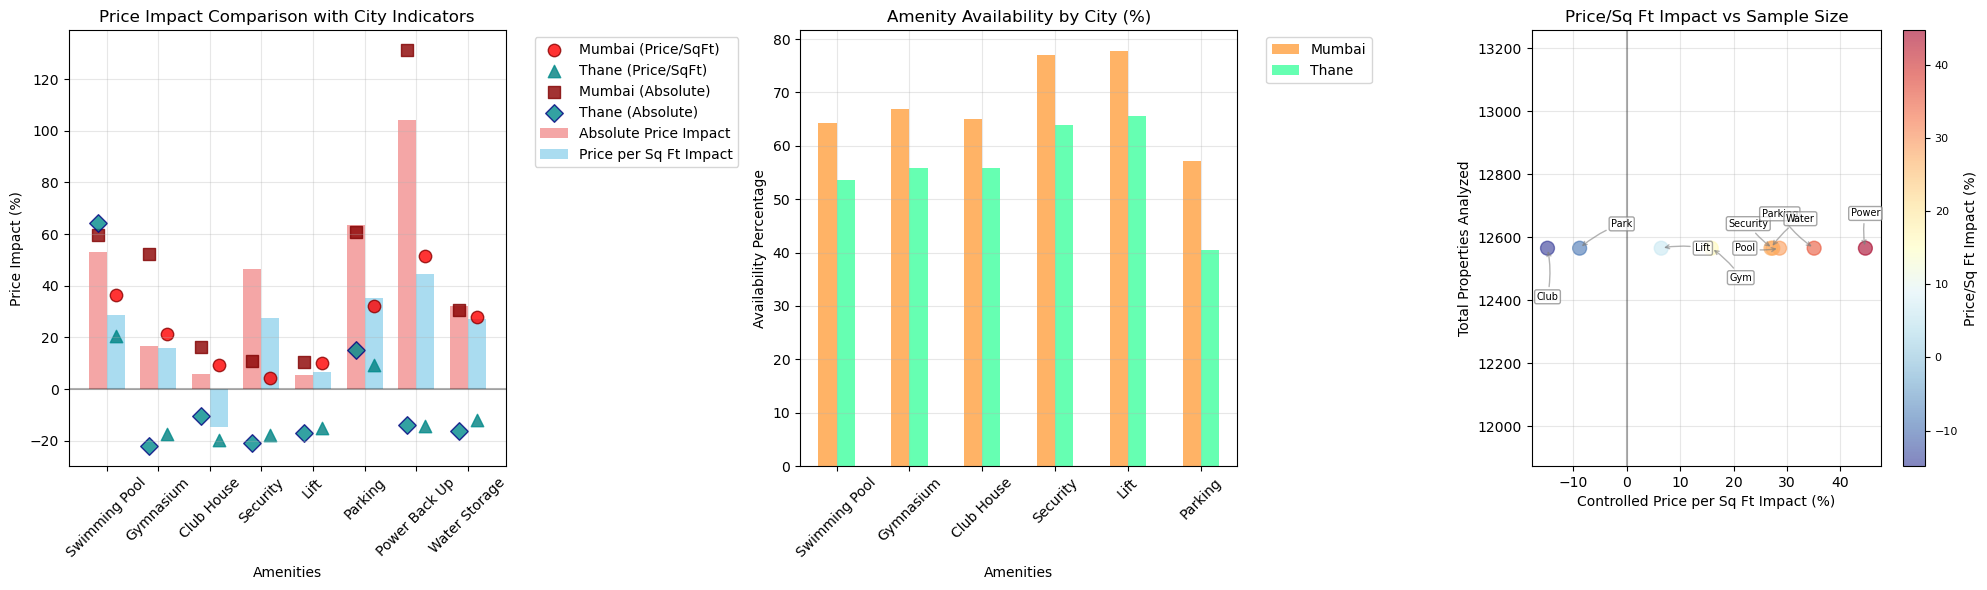


🎯 FEATURE VALUE ANALYSIS & INVESTMENT RECOMMENDATIONS (PRICE/SQ FT)
🔥 HIGH-VALUE AMENITIES (>10% price per sq ft impact):
  • Power Back Up: +44.7% price/sq ft impact
    (₹25316 vs ₹19339 per sq ft | +104.0% absolute price)
  • Parking: +35.1% price/sq ft impact
    (₹27667 vs ₹18459 per sq ft | +63.4% absolute price)
  • Swimming Pool: +28.6% price/sq ft impact
    (₹26402 vs ₹18274 per sq ft | +53.1% absolute price)
  • Security: +27.4% price/sq ft impact
    (₹25135 vs ₹18120 per sq ft | +46.4% absolute price)
  • Water Storage: +27.0% price/sq ft impact
    (₹25493 vs ₹19022 per sq ft | +32.3% absolute price)
  • Gymnasium: +15.8% price/sq ft impact
    (₹25736 vs ₹18891 per sq ft | +16.6% absolute price)

⭐ MODERATE-VALUE AMENITIES (5-10% price per sq ft impact):
  • Lift: +6.5% price/sq ft impact (+5.6% absolute)

📊 CITY-SPECIFIC INSIGHTS (Price per Sq Ft Analysis):
• Mumbai top price/sq ft drivers: ['Power Back Up (+51.4%)', 'Swimming Pool (+36.5%)', 'Parking (+32.1%)']
• Than

In [15]:
# 5. Feature & Amenity Impact on Price

print("\n\n5. FEATURE & AMENITY IMPACT ON PRICE")
print("="*50)

# Define key amenities to analyze
key_amenities = ['Swimming Pool', 'Gymnasium', 'Club House', 'Security', 'Lift', 
                'Parking', 'Power Back Up', 'Water Storage', 'Park']

# Ensure we have valid price and area data for price per sq ft analysis
amenity_analysis_data = df_filtered[
    (df_filtered['Price_Clean'].notna()) & 
    (df_filtered['sqft_Price_Clean'].notna()) & 
    (df_filtered['sqft_Price_Clean'] > 0)
].copy()

print(f"Properties analyzed for amenity impact (with valid price/sqft data): {len(amenity_analysis_data)}")

# Create binary columns for all amenities with proper handling
for amenity in key_amenities:
    if amenity in amenity_analysis_data.columns:
        if amenity == 'Parking':
            # Special handling for parking which has descriptive values
            amenity_analysis_data[f'{amenity}_Binary'] = amenity_analysis_data[amenity].astype(str).str.contains('Covered|Open', case=False, na=False).astype(int)
        else:
            # Standard handling for Y/N, 1/0 amenities
            amenity_analysis_data[f'{amenity}_Binary'] = pd.to_numeric(amenity_analysis_data[amenity].replace({'Y': 1, 'N': 0}), errors='coerce').fillna(0).astype(int)

# Controlled amenity impact analysis using PRICE PER SQUARE FOOT
print("\n" + "="*70)
print("CONTROLLED AMENITY IMPACT ANALYSIS (PRICE PER SQ FT BASIS)")
print("="*70)
print("Note: Analysis based on price per sq ft to account for property size differences")

amenity_impact_controlled = {}

# Available amenity columns in binary format
available_amenities = [f'{amenity}_Binary' for amenity in key_amenities if f'{amenity}_Binary' in amenity_analysis_data.columns]

for amenity in key_amenities:
    if f'{amenity}_Binary' in amenity_analysis_data.columns:
        print(f"\nAnalyzing price per sq ft impact of {amenity}...")
        
        # Get properties with and without this specific amenity
        with_amenity_mask = amenity_analysis_data[f'{amenity}_Binary'] == 1
        without_amenity_mask = amenity_analysis_data[f'{amenity}_Binary'] == 0
        
        with_amenity_data = amenity_analysis_data[with_amenity_mask]
        without_amenity_data = amenity_analysis_data[without_amenity_mask]
        
        if len(with_amenity_data) > 10 and len(without_amenity_data) > 10:  # Minimum threshold for meaningful comparison
            # Method 1: Direct comparison using price per sq ft
            avg_sqft_price_with_direct = with_amenity_data['sqft_Price_Clean'].mean()
            avg_sqft_price_without_direct = without_amenity_data['sqft_Price_Clean'].mean()
            direct_sqft_impact = ((avg_sqft_price_with_direct - avg_sqft_price_without_direct) / avg_sqft_price_without_direct) * 100
            
            # Also calculate absolute price impact for comparison
            avg_with_direct = with_amenity_data['Price_Clean'].mean()
            avg_without_direct = without_amenity_data['Price_Clean'].mean()
            direct_impact = ((avg_with_direct - avg_without_direct) / avg_without_direct) * 100
            
            # Method 2: Controlled comparison using price per sq ft - match properties with similar amenity profiles
            # Calculate total other amenities for each property (excluding the current amenity)
            other_amenities = [col for col in available_amenities if col != f'{amenity}_Binary']
            
            if other_amenities:  # Only if we have other amenities to control for
                with_amenity_data['Other_Amenities_Count'] = with_amenity_data[other_amenities].sum(axis=1)
                without_amenity_data['Other_Amenities_Count'] = without_amenity_data[other_amenities].sum(axis=1)
                
                # Find properties with similar amenity counts for fair comparison using price per sq ft
                controlled_sqft_comparisons = []
                controlled_abs_comparisons = []
                
                for other_count in range(int(with_amenity_data['Other_Amenities_Count'].max()) + 1):
                    with_similar = with_amenity_data[with_amenity_data['Other_Amenities_Count'] == other_count]
                    without_similar = without_amenity_data[without_amenity_data['Other_Amenities_Count'] == other_count]
                    
                    if len(with_similar) >= 3 and len(without_similar) >= 3:  # Minimum for meaningful comparison
                        # Price per sq ft comparison (main analysis)
                        avg_sqft_with_controlled = with_similar['sqft_Price_Clean'].mean()
                        avg_sqft_without_controlled = without_similar['sqft_Price_Clean'].mean()
                        controlled_sqft_comparisons.append((avg_sqft_with_controlled, avg_sqft_without_controlled, len(with_similar), len(without_similar)))
                        
                        # Absolute price comparison (for reference)
                        avg_with_controlled = with_similar['Price_Clean'].mean()
                        avg_without_controlled = without_similar['Price_Clean'].mean()
                        controlled_abs_comparisons.append((avg_with_controlled, avg_without_controlled, len(with_similar), len(without_similar)))
                
                if controlled_sqft_comparisons:
                    # Weight the comparisons by sample sizes - PRICE PER SQ FT
                    total_weight = sum(comp[2] + comp[3] for comp in controlled_sqft_comparisons)
                    weighted_sqft_impact = sum(
                        ((comp[0] - comp[1]) / comp[1] * 100) * (comp[2] + comp[3]) / total_weight 
                        for comp in controlled_sqft_comparisons
                    )
                    
                    # Weight the comparisons by sample sizes - ABSOLUTE PRICE (for comparison)
                    weighted_abs_impact = sum(
                        ((comp[0] - comp[1]) / comp[1] * 100) * (comp[2] + comp[3]) / total_weight 
                        for comp in controlled_abs_comparisons
                    )
                    
                    amenity_impact_controlled[amenity] = {
                        'Direct_Price_Impact_%': direct_impact,
                        'Direct_SqFt_Impact_%': direct_sqft_impact,
                        'Controlled_Price_Impact_%': weighted_abs_impact,
                        'Controlled_SqFt_Impact_%': weighted_sqft_impact,
                        'Properties_With': len(with_amenity_data),
                        'Properties_Without': len(without_amenity_data),
                        'Controlled_Comparisons': len(controlled_sqft_comparisons),
                        'Avg_SqFt_Price_With': avg_sqft_price_with_direct,
                        'Avg_SqFt_Price_Without': avg_sqft_price_without_direct
                    }
                else:
                    amenity_impact_controlled[amenity] = {
                        'Direct_Price_Impact_%': direct_impact,
                        'Direct_SqFt_Impact_%': direct_sqft_impact,
                        'Controlled_Price_Impact_%': direct_impact,
                        'Controlled_SqFt_Impact_%': direct_sqft_impact,
                        'Properties_With': len(with_amenity_data),
                        'Properties_Without': len(without_amenity_data),
                        'Controlled_Comparisons': 0,
                        'Avg_SqFt_Price_With': avg_sqft_price_with_direct,
                        'Avg_SqFt_Price_Without': avg_sqft_price_without_direct
                    }
            else:
                amenity_impact_controlled[amenity] = {
                    'Direct_Price_Impact_%': direct_impact,
                    'Direct_SqFt_Impact_%': direct_sqft_impact,
                    'Controlled_Price_Impact_%': direct_impact,
                    'Controlled_SqFt_Impact_%': direct_sqft_impact,
                    'Properties_With': len(with_amenity_data),
                    'Properties_Without': len(without_amenity_data),
                    'Controlled_Comparisons': 0,
                    'Avg_SqFt_Price_With': avg_sqft_price_with_direct,
                    'Avg_SqFt_Price_Without': avg_sqft_price_without_direct
                }

# Convert to DataFrame for analysis
if amenity_impact_controlled:
    controlled_amenity_df = pd.DataFrame(amenity_impact_controlled).T.round(2)
    
    print("\nControlled Amenity Impact Analysis (Price per Sq Ft Focus):")
    print("="*75)
    print("Note: Primary analysis based on price per sq ft to control for property size")
    print("\nKey Metrics:")
    print("- Controlled_SqFt_Impact_%: TRUE amenity value impact on price per sq ft")
    print("- Controlled_Price_Impact_%: Traditional absolute price impact (for comparison)")
    
    # Sort by price per sq ft impact (the main metric)
    controlled_sorted = controlled_amenity_df.sort_values('Controlled_SqFt_Impact_%', ascending=False)
    
    # Display key columns with better formatting
    display_columns = ['Controlled_SqFt_Impact_%', 'Controlled_Price_Impact_%', 'Properties_With', 'Properties_Without', 
                      'Avg_SqFt_Price_With', 'Avg_SqFt_Price_Without', 'Controlled_Comparisons']
    print(controlled_sorted[display_columns])
    
    print("\nKey Insights:")
    for amenity in controlled_sorted.index[:5]:  # Top 5 amenities
        sqft_impact = controlled_sorted.loc[amenity, 'Controlled_SqFt_Impact_%']
        price_impact = controlled_sorted.loc[amenity, 'Controlled_Price_Impact_%']
        with_price = controlled_sorted.loc[amenity, 'Avg_SqFt_Price_With']
        without_price = controlled_sorted.loc[amenity, 'Avg_SqFt_Price_Without']
        
        print(f"• {amenity}:")
        print(f"  - Price/sq ft impact: {sqft_impact:+.1f}% (₹{with_price:.0f} vs ₹{without_price:.0f})")
        print(f"  - Absolute price impact: {price_impact:+.1f}% (traditional method)")
        print(f"  - Size-controlled analysis {'DIFFERS significantly' if abs(sqft_impact - price_impact) > 5 else 'aligns with traditional'}")
        print()

    # City-wise controlled amenity analysis using price per sq ft
    print("\n" + "="*60)
    print("CITY-WISE CONTROLLED AMENITY IMPACT ANALYSIS (PRICE/SQ FT)")
    print("="*60)

    city_amenity_results_sqft = {}
    city_amenity_results_abs = {}
    
    for city in ['Mumbai', 'Thane']:
        city_data = amenity_analysis_data[amenity_analysis_data['City'] == city].copy()
        print(f"\n🏙️ {city.upper()} ({len(city_data)} properties):")
        
        city_impacts_sqft = {}
        city_impacts_abs = {}
        
        for amenity in key_amenities:
            if f'{amenity}_Binary' in city_data.columns and len(city_data) > 20:
                with_amenity_mask = city_data[f'{amenity}_Binary'] == 1
                without_amenity_mask = city_data[f'{amenity}_Binary'] == 0
                
                with_amenity_city = city_data[with_amenity_mask]
                without_amenity_city = city_data[without_amenity_mask]
                
                if len(with_amenity_city) > 5 and len(without_amenity_city) > 5:
                    # Controlled comparison within city using both metrics
                    other_amenities = [col for col in available_amenities if col != f'{amenity}_Binary' and col in city_data.columns]
                    
                    if other_amenities:
                        with_amenity_city['Other_Amenities_Count'] = with_amenity_city[other_amenities].sum(axis=1)
                        without_amenity_city['Other_Amenities_Count'] = without_amenity_city[other_amenities].sum(axis=1)
                        
                        controlled_city_sqft_comparisons = []
                        controlled_city_abs_comparisons = []
                        
                        for other_count in range(int(max(with_amenity_city['Other_Amenities_Count'].max(), 
                                                       without_amenity_city['Other_Amenities_Count'].max())) + 1):
                            with_similar = with_amenity_city[with_amenity_city['Other_Amenities_Count'] == other_count]
                            without_similar = without_amenity_city[without_amenity_city['Other_Amenities_Count'] == other_count]
                            
                            if len(with_similar) >= 2 and len(without_similar) >= 2:
                                # Price per sq ft comparison
                                avg_sqft_with = with_similar['sqft_Price_Clean'].mean()
                                avg_sqft_without = without_similar['sqft_Price_Clean'].mean()
                                controlled_city_sqft_comparisons.append((avg_sqft_with, avg_sqft_without, len(with_similar), len(without_similar)))
                                
                                # Absolute price comparison
                                avg_with = with_similar['Price_Clean'].mean()
                                avg_without = without_similar['Price_Clean'].mean()
                                controlled_city_abs_comparisons.append((avg_with, avg_without, len(with_similar), len(without_similar)))
                        
                        if controlled_city_sqft_comparisons:
                            # Calculate weighted impacts for both metrics
                            total_weight = sum(comp[2] + comp[3] for comp in controlled_city_sqft_comparisons)
                            
                            # Price per sq ft impact (primary metric)
                            weighted_sqft_impact = sum(
                                ((comp[0] - comp[1]) / comp[1] * 100) * (comp[2] + comp[3]) / total_weight 
                                for comp in controlled_city_sqft_comparisons
                            )
                            city_impacts_sqft[amenity] = weighted_sqft_impact
                            
                            # Absolute price impact (secondary metric)
                            weighted_abs_impact = sum(
                                ((comp[0] - comp[1]) / comp[1] * 100) * (comp[2] + comp[3]) / total_weight 
                                for comp in controlled_city_abs_comparisons
                            )
                            city_impacts_abs[amenity] = weighted_abs_impact
                        else:
                            # Fallback to direct comparison
                            avg_sqft_with = with_amenity_city['sqft_Price_Clean'].mean()
                            avg_sqft_without = without_amenity_city['sqft_Price_Clean'].mean()
                            city_impacts_sqft[amenity] = ((avg_sqft_with - avg_sqft_without) / avg_sqft_without) * 100
                            
                            avg_with = with_amenity_city['Price_Clean'].mean()
                            avg_without = without_amenity_city['Price_Clean'].mean()
                            city_impacts_abs[amenity] = ((avg_with - avg_without) / avg_without) * 100
        
        # Sort and display top amenities for this city
        if city_impacts_sqft:
            sorted_city_amenities_sqft = sorted(city_impacts_sqft.items(), key=lambda x: x[1], reverse=True)
            sorted_city_amenities_abs = sorted(city_impacts_abs.items(), key=lambda x: x[1], reverse=True)
            
            city_amenity_results_sqft[city] = dict(sorted_city_amenities_sqft)
            city_amenity_results_abs[city] = dict(sorted_city_amenities_abs)
            
            print(f"Top amenities by controlled price per sq ft impact:")
            for amenity, impact in sorted_city_amenities_sqft:
                abs_impact = city_impacts_abs.get(amenity, 0)
                print(f"  • {amenity}: {impact:+.1f}% price/sq ft impact (vs {abs_impact:+.1f}% absolute price)")
        
        else:
            print("  Insufficient data for controlled analysis in this city")

    # Cross-city comparison using price per sq ft
    print("\n" + "="*60)
    print("CROSS-CITY AMENITY PREFERENCE COMPARISON (PRICE/SQ FT)")
    print("="*60)
    
    if len(city_amenity_results_sqft) == 2:
        mumbai_prefs_sqft = city_amenity_results_sqft.get('Mumbai', {})
        thane_prefs_sqft = city_amenity_results_sqft.get('Thane', {})
        
        mumbai_prefs_abs = city_amenity_results_abs.get('Mumbai', {})
        thane_prefs_abs = city_amenity_results_abs.get('Thane', {})
        
        print("Amenity preference differences between cities (Price per Sq Ft Analysis):")
        all_amenities = set(mumbai_prefs_sqft.keys()) | set(thane_prefs_sqft.keys())
        
        preference_comparison_sqft = []
        for amenity in all_amenities:
            mumbai_sqft_impact = mumbai_prefs_sqft.get(amenity, 0)
            thane_sqft_impact = thane_prefs_sqft.get(amenity, 0)
            difference_sqft = mumbai_sqft_impact - thane_sqft_impact
            
            mumbai_abs_impact = mumbai_prefs_abs.get(amenity, 0)
            thane_abs_impact = thane_prefs_abs.get(amenity, 0)
            difference_abs = mumbai_abs_impact - thane_abs_impact
            
            preference_comparison_sqft.append((amenity, mumbai_sqft_impact, thane_sqft_impact, difference_sqft, 
                                             mumbai_abs_impact, thane_abs_impact, difference_abs))
        
        # Sort by absolute difference in price per sq ft impact
        preference_comparison_sqft.sort(key=lambda x: abs(x[3]), reverse=True)
        
        print(f"\n{'Amenity':<15} {'Mumbai':<12} {'Thane':<12} {'Diff':<10} {'Preference (SqFt)'}")
        print("-" * 70)
        for amenity, mum_sqft, thane_sqft, diff_sqft, mum_abs, thane_abs, diff_abs in preference_comparison_sqft:
            if abs(diff_sqft) > 2:  # Only show significant differences
                preference = "Mumbai" if diff_sqft > 0 else "Thane" if diff_sqft < 0 else "Similar"
                print(f"{amenity:<15} {mum_sqft:>+9.1f}%  {thane_sqft:>+9.1f}%  {diff_sqft:>+7.1f}%  {preference}")
                
        print(f"\nNote: Analysis shows price/sq ft impact differences between cities")
        print(f"Positive values indicate the amenity increases price/sq ft in that city")

    # Visualizations
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))
    
    # Adjust spacing for better layout
    plt.subplots_adjust(wspace=0.3)

    # Plot 1: Combined Price per Sq Ft vs Absolute Price Impact with City Indicators
    if not controlled_amenity_df.empty:
        comparison_data = controlled_amenity_df[['Controlled_Price_Impact_%', 'Controlled_SqFt_Impact_%']].head(8)
        
        # Create combined plot with city-specific data overlaid
        x = range(len(comparison_data))
        width = 0.35
        
        # Overall bars
        bars1 = ax1.bar([i - width/2 for i in x], comparison_data['Controlled_Price_Impact_%'], 
                       width, label='Absolute Price Impact', color='lightcoral', alpha=0.7)
        bars2 = ax1.bar([i + width/2 for i in x], comparison_data['Controlled_SqFt_Impact_%'], 
                       width, label='Price per Sq Ft Impact', color='skyblue', alpha=0.7)
        
        # Add city-specific indicators as markers
        if city_amenity_results_sqft and city_amenity_results_abs:
            for i, amenity in enumerate(comparison_data.index):
                # Price per sq ft city indicators
                mumbai_sqft_impact = city_amenity_results_sqft.get('Mumbai', {}).get(amenity, 0)
                thane_sqft_impact = city_amenity_results_sqft.get('Thane', {}).get(amenity, 0)
                
                # Absolute price city indicators  
                mumbai_abs_impact = city_amenity_results_abs.get('Mumbai', {}).get(amenity, 0)
                thane_abs_impact = city_amenity_results_abs.get('Thane', {}).get(amenity, 0)
                
                # Add Mumbai markers for price per sq ft (circles on blue bars)
                if abs(mumbai_sqft_impact) > 1:  # Only show significant impacts
                    ax1.scatter(i + width/2, mumbai_sqft_impact, color='red', s=80, marker='o', 
                              label='Mumbai (Price/SqFt)' if i == 0 else "", alpha=0.8, edgecolor='darkred')
                
                # Add Thane markers for price per sq ft (triangles on blue bars)
                if abs(thane_sqft_impact) > 1:  # Only show significant impacts
                    ax1.scatter(i + width/2, thane_sqft_impact, color='teal', s=80, marker='^', 
                              label='Thane (Price/SqFt)' if i == 0 else "", alpha=0.8, edgecolor='darkcyan')
                
                # Add Mumbai markers for absolute price (squares on red bars)
                if abs(mumbai_abs_impact) > 1:  # Only show significant impacts
                    ax1.scatter(i - width/2, mumbai_abs_impact, color='darkred', s=80, marker='s', 
                              label='Mumbai (Absolute)' if i == 0 else "", alpha=0.8, edgecolor='maroon')
                
                # Add Thane markers for absolute price (diamonds on red bars)
                if abs(thane_abs_impact) > 1:  # Only show significant impacts
                    ax1.scatter(i - width/2, thane_abs_impact, color='darkcyan', s=80, marker='D', 
                              label='Thane (Absolute)' if i == 0 else "", alpha=0.8, edgecolor='navy')
        
        ax1.set_title('Price Impact Comparison with City Indicators')
        ax1.set_xlabel('Amenities')
        ax1.set_ylabel('Price Impact (%)')
        ax1.set_xticks(x)
        ax1.set_xticklabels(comparison_data.index, rotation=45)
        ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        ax1.grid(True, alpha=0.3)
        ax1.axhline(y=0, color='black', linestyle='-', alpha=0.3)

    # Plot 2: Amenity availability by city
    city_amenity_availability = {}
    for city in ['Mumbai', 'Thane']:
        city_data = amenity_analysis_data[amenity_analysis_data['City'] == city]
        if len(city_data) > 0:
            city_amenities = {}
            for amenity in key_amenities[:6]:  # Top 6 amenities
                if f'{amenity}_Binary' in city_data.columns:
                    availability = (city_data[f'{amenity}_Binary'].sum() / len(city_data)) * 100
                    city_amenities[amenity] = availability
            city_amenity_availability[city] = city_amenities
    
    if city_amenity_availability:
        availability_df = pd.DataFrame(city_amenity_availability)
        availability_df.plot(kind='bar', ax=ax2, color=['#FFB366', '#66FFB2'])
        ax2.set_title('Amenity Availability by City (%)')
        ax2.set_xlabel('Amenities')
        ax2.set_ylabel('Availability Percentage')
        ax2.tick_params(axis='x', rotation=45)
        ax2.legend(['Mumbai', 'Thane'], bbox_to_anchor=(1.05, 1), loc='upper left')
        ax2.grid(True, alpha=0.3)

    # Plot 3: Price per Sq Ft Impact vs Sample Size scatter plot
    if not controlled_amenity_df.empty:
        x_vals = controlled_amenity_df['Controlled_SqFt_Impact_%']
        y_vals = controlled_amenity_df['Properties_With'] + controlled_amenity_df['Properties_Without']
        
        scatter = ax3.scatter(x_vals, y_vals, s=100, alpha=0.6, c=x_vals, cmap='RdYlBu_r')
        
        # Add amenity labels with strategic positioning to avoid overlap
        import numpy as np
        
        # Define positioning angles and distances to spread labels around points
        angles = np.array([0, 45, 90, 135, 180, 225, 270, 315, 30]) * np.pi / 180  # Convert to radians
        distances = [25, 30, 35, 25, 30, 35, 25, 30, 35]  # Different distances for variation
        
        for i, amenity in enumerate(controlled_amenity_df.index):
            # Shorten amenity names for better readability
            short_amenity = amenity.replace('Swimming Pool', 'Pool').replace('Gymnasium', 'Gym').replace('Club House', 'Club').replace('Power Back Up', 'Power').replace('Water Storage', 'Water')
            
            # Use different angles for each point to spread them out
            angle = angles[i % len(angles)]
            distance = distances[i % len(distances)]
            
            # Calculate offset position
            x_offset = distance * np.cos(angle)
            y_offset = distance * np.sin(angle)
            
            # Adjust positioning based on data point location to avoid going outside plot area
            x_pos = x_vals.iloc[i]
            y_pos = y_vals.iloc[i]
            
            # Adjust offsets if they would push labels outside reasonable bounds
            if x_pos + x_offset < x_vals.min() - 5:
                x_offset = abs(x_offset)  # Push to right
            elif x_pos + x_offset > x_vals.max() + 5:
                x_offset = -abs(x_offset)  # Push to left
            
            if y_pos + y_offset < y_vals.min() - 20:
                y_offset = abs(y_offset)  # Push up
            elif y_pos + y_offset > y_vals.max() + 20:
                y_offset = -abs(y_offset)  # Push down
                
            ax3.annotate(short_amenity, (x_pos, y_pos), 
                        xytext=(x_offset, y_offset), textcoords='offset points', 
                        fontsize=7, ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='gray'),
                        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.1', color='gray', alpha=0.6))
        
        ax3.set_title('Price/Sq Ft Impact vs Sample Size')
        ax3.set_xlabel('Controlled Price per Sq Ft Impact (%)')
        ax3.set_ylabel('Total Properties Analyzed')
        ax3.grid(True, alpha=0.3)
        ax3.axvline(x=0, color='black', linestyle='-', alpha=0.3)
        cbar = plt.colorbar(scatter, ax=ax3, label='Price/Sq Ft Impact (%)')
        cbar.ax.tick_params(labelsize=8)

    plt.tight_layout()
    plt.show()

    # Feature value analysis and recommendations based on price per sq ft
    print("\n" + "="*70)
    print("🎯 FEATURE VALUE ANALYSIS & INVESTMENT RECOMMENDATIONS (PRICE/SQ FT)")
    print("="*70)

    if not controlled_amenity_df.empty:
        # Use price per sq ft impact as the primary metric
        high_impact_amenities = controlled_amenity_df[controlled_amenity_df['Controlled_SqFt_Impact_%'] > 10].sort_values('Controlled_SqFt_Impact_%', ascending=False)
        moderate_impact_amenities = controlled_amenity_df[(controlled_amenity_df['Controlled_SqFt_Impact_%'] >= 5) & (controlled_amenity_df['Controlled_SqFt_Impact_%'] <= 10)]
        low_impact_amenities = controlled_amenity_df[controlled_amenity_df['Controlled_SqFt_Impact_%'] < 5]

        print("🔥 HIGH-VALUE AMENITIES (>10% price per sq ft impact):")
        for amenity in high_impact_amenities.index:
            sqft_impact = high_impact_amenities.loc[amenity, 'Controlled_SqFt_Impact_%']
            abs_impact = high_impact_amenities.loc[amenity, 'Controlled_Price_Impact_%']
            with_price = high_impact_amenities.loc[amenity, 'Avg_SqFt_Price_With']
            without_price = high_impact_amenities.loc[amenity, 'Avg_SqFt_Price_Without']
            print(f"  • {amenity}: +{sqft_impact:.1f}% price/sq ft impact")
            print(f"    (₹{with_price:.0f} vs ₹{without_price:.0f} per sq ft | {abs_impact:+.1f}% absolute price)")
        
        print("\n⭐ MODERATE-VALUE AMENITIES (5-10% price per sq ft impact):")
        for amenity in moderate_impact_amenities.index:
            sqft_impact = moderate_impact_amenities.loc[amenity, 'Controlled_SqFt_Impact_%']
            abs_impact = moderate_impact_amenities.loc[amenity, 'Controlled_Price_Impact_%']
            print(f"  • {amenity}: +{sqft_impact:.1f}% price/sq ft impact ({abs_impact:+.1f}% absolute)")

        print("\n📊 CITY-SPECIFIC INSIGHTS (Price per Sq Ft Analysis):")
        if city_amenity_results_sqft:
            mumbai_top = sorted(mumbai_prefs_sqft.items(), key=lambda x: x[1], reverse=True)[:3]
            thane_top = sorted(thane_prefs_sqft.items(), key=lambda x: x[1], reverse=True)[:3]
            
            print("• Mumbai top price/sq ft drivers:", [f"{k} (+{v:.1f}%)" for k, v in mumbai_top])
            print("• Thane top price/sq ft drivers:", [f"{k} (+{v:.1f}%)" for k, v in thane_top])
        
        print("\n💡 INVESTMENT RECOMMENDATIONS:")
        print("• 🎯 SIZE-CONTROLLED ANALYSIS: Price per sq ft eliminates apartment size bias")
        print("• 🏢 Focus on amenities with high price/sq ft impact for better value per rupee")
        print("• 📍 Consider city-specific amenity preferences when choosing locations")
        print("• 🔍 Amenities showing big differences between absolute vs price/sq ft impact may be")
        print("    correlated with property size (luxury properties tend to be larger)")
        
        # Highlight amenities where size matters
        print("\n⚠️ SIZE-CORRELATION INSIGHTS:")
        for amenity in controlled_amenity_df.index:
            sqft_impact = controlled_amenity_df.loc[amenity, 'Controlled_SqFt_Impact_%']
            abs_impact = controlled_amenity_df.loc[amenity, 'Controlled_Price_Impact_%']
            difference = abs_impact - sqft_impact
            
            if abs(difference) > 8:  # Significant difference
                if difference > 0:
                    print(f"  • {amenity}: Likely correlated with LARGER properties (+{difference:.1f}% size effect)")
                else:
                    print(f"  • {amenity}: Likely correlated with SMALLER properties ({difference:.1f}% size effect)")
        
        print("\n🚀 KEY TAKEAWAY:")
        print("Price per sq ft analysis provides TRUE amenity value, controlling for property size.")
        print("Use this for fair comparison when properties of different sizes are being compared.")

else:
    print("Insufficient data for controlled amenity analysis")

In [11]:
# DETAILED INVESTIGATION: Why do Thane amenities appear cheaper?

print("\n" + "="*80)
print("🔍 THANE AMENITY PRICING INVESTIGATION")
print("="*80)

# Focus on Thane data with amenities
thane_investigation = amenity_analysis_data[amenity_analysis_data['City'] == 'Thane'].copy()
print(f"Total Thane properties in analysis: {len(thane_investigation)}")

# Let's examine specific amenities that show negative impact in Thane
negative_amenities = []
for amenity in key_amenities:
    if amenity in city_amenity_results_sqft.get('Thane', {}):
        impact = city_amenity_results_sqft['Thane'][amenity]
        if impact < 0:
            negative_amenities.append((amenity, impact))

negative_amenities.sort(key=lambda x: x[1])  # Sort by impact (most negative first)

print(f"\nAmenities with NEGATIVE price/sq ft impact in Thane:")
for amenity, impact in negative_amenities:
    print(f"• {amenity}: {impact:.1f}%")

# Let's examine the property characteristics for each negative impact amenity
print("\n" + "="*60)
print("DETAILED BREAKDOWN FOR NEGATIVE IMPACT AMENITIES")
print("="*60)

for amenity, impact in negative_amenities[:3]:  # Top 3 most negative
    print(f"\n📊 {amenity.upper()} ANALYSIS IN THANE:")
    print("-" * 50)
    
    # Get properties with and without this amenity in Thane
    amenity_col = f'{amenity}_Binary'
    if amenity_col in thane_investigation.columns:
        with_amenity = thane_investigation[thane_investigation[amenity_col] == 1]
        without_amenity = thane_investigation[thane_investigation[amenity_col] == 0]
        
        print(f"Properties WITH {amenity}: {len(with_amenity)}")
        print(f"Properties WITHOUT {amenity}: {len(without_amenity)}")
        
        if len(with_amenity) > 0 and len(without_amenity) > 0:
            # Detailed statistics
            print(f"\nWITH {amenity}:")
            print(f"  - Avg Price: ₹{with_amenity['Price_Clean'].mean()/10000000:.2f} Cr")
            print(f"  - Avg Price/sq ft: ₹{with_amenity['sqft_Price_Clean'].mean():.0f}")
            if 'Area' in with_amenity.columns:
                print(f"  - Avg Area: {with_amenity['Area'].mean():.0f} sq ft")
            
            print(f"\nWITHOUT {amenity}:")
            print(f"  - Avg Price: ₹{without_amenity['Price_Clean'].mean()/10000000:.2f} Cr")
            print(f"  - Avg Price/sq ft: ₹{without_amenity['sqft_Price_Clean'].mean():.0f}")
            if 'Area' in without_amenity.columns:
                print(f"  - Avg Area: {without_amenity['Area'].mean():.0f} sq ft")
            
            # Calculate the impacts
            price_impact = ((with_amenity['Price_Clean'].mean() - without_amenity['Price_Clean'].mean()) / without_amenity['Price_Clean'].mean()) * 100
            sqft_impact = ((with_amenity['sqft_Price_Clean'].mean() - without_amenity['sqft_Price_Clean'].mean()) / without_amenity['sqft_Price_Clean'].mean()) * 100
            
            print(f"\nIMPACT ANALYSIS:")
            print(f"  - Absolute Price Impact: {price_impact:+.1f}%")
            print(f"  - Price/sq ft Impact: {sqft_impact:+.1f}%")
            
            # Check if this is a property type or location issue
            print(f"\nPROPERTY TYPE BREAKDOWN:")
            if 'Property Type' in thane_investigation.columns:
                print("WITH amenity:")
                prop_types_with = with_amenity['Property Type'].value_counts().head(3)
                for prop_type, count in prop_types_with.items():
                    pct = (count / len(with_amenity)) * 100
                    avg_sqft_price = with_amenity[with_amenity['Property Type'] == prop_type]['sqft_Price_Clean'].mean()
                    print(f"  - {prop_type}: {count} props ({pct:.1f}%) - Avg ₹{avg_sqft_price:.0f}/sq ft")
                
                print("WITHOUT amenity:")
                prop_types_without = without_amenity['Property Type'].value_counts().head(3)
                for prop_type, count in prop_types_without.items():
                    pct = (count / len(without_amenity)) * 100
                    avg_sqft_price = without_amenity[without_amenity['Property Type'] == prop_type]['sqft_Price_Clean'].mean()
                    print(f"  - {prop_type}: {count} props ({pct:.1f}%) - Avg ₹{avg_sqft_price:.0f}/sq ft")

# Let's also check area-based breakdown
print("\n" + "="*60)
print("AREA-BASED ANALYSIS FOR THANE")
print("="*60)

if 'Area' in thane_investigation.columns:
    # Create area bins
    area_bins = [0, 500, 1000, 1500, 2000, float('inf')]
    area_labels = ['<500', '500-1000', '1000-1500', '1500-2000', '2000+']
    thane_investigation['Area_Bin'] = pd.cut(thane_investigation['Area'], bins=area_bins, labels=area_labels, include_lowest=True)
    
    print("Price/sq ft by Area Range:")
    area_analysis = thane_investigation.groupby('Area_Bin').agg({
        'sqft_Price_Clean': ['mean', 'count'],
        'Price_Clean': 'mean'
    }).round(0)
    
    area_analysis.columns = ['Avg_Price_per_sqft', 'Property_Count', 'Avg_Total_Price']
    area_analysis['Avg_Total_Price_Cr'] = (area_analysis['Avg_Total_Price'] / 10000000).round(2)
    print(area_analysis[['Avg_Price_per_sqft', 'Property_Count', 'Avg_Total_Price_Cr']])
    
    # Check amenity distribution across area ranges
    print(f"\nAmenity distribution across area ranges:")
    for amenity in ['Swimming Pool', 'Parking', 'Security']:
        amenity_col = f'{amenity}_Binary'
        if amenity_col in thane_investigation.columns:
            print(f"\n{amenity}:")
            amenity_by_area = thane_investigation.groupby('Area_Bin')[amenity_col].agg(['mean', 'count'])
            amenity_by_area.columns = ['Amenity_Percentage', 'Total_Properties']
            amenity_by_area['Amenity_Percentage'] = (amenity_by_area['Amenity_Percentage'] * 100).round(1)
            print(amenity_by_area)

print("\n" + "="*80)
print("🔍 POSSIBLE EXPLANATIONS FOR THANE NEGATIVE AMENITY IMPACT:")
print("="*80)
print("1. 💡 REVERSE CAUSALITY: In Thane, amenities might be added to MAKE")
print("   cheaper/smaller properties more marketable")
print("2. 🏘️ LOCATION EFFECT: Properties with amenities might be in less")
print("   premium locations within Thane")  
print("3. 📊 PROPERTY MIX: Amenities might be more common in budget/mid-range")
print("   developments rather than luxury projects")
print("4. 🏗️ DEVELOPER STRATEGY: Builders might use amenities to compensate")
print("   for other limitations (location, size, etc.)")
print("5. 📈 MARKET MATURITY: Thane market might not yet fully price in")
print("   amenity premiums like Mumbai does")
print("="*80)


🔍 THANE AMENITY PRICING INVESTIGATION
Total Thane properties in analysis: 4075

Amenities with NEGATIVE price/sq ft impact in Thane:
• Club House: -19.7%
• Security: -17.8%
• Gymnasium: -17.6%
• Lift: -15.0%
• Power Back Up: -14.2%
• Water Storage: -11.9%
• Park: -4.2%

DETAILED BREAKDOWN FOR NEGATIVE IMPACT AMENITIES

📊 CLUB HOUSE ANALYSIS IN THANE:
--------------------------------------------------
Properties WITH Club House: 2275
Properties WITHOUT Club House: 1800

WITH Club House:
  - Avg Price: ₹1.23 Cr
  - Avg Price/sq ft: ₹12415

WITHOUT Club House:
  - Avg Price: ₹0.90 Cr
  - Avg Price/sq ft: ₹12471

IMPACT ANALYSIS:
  - Absolute Price Impact: +36.5%
  - Price/sq ft Impact: -0.4%

PROPERTY TYPE BREAKDOWN:

📊 SECURITY ANALYSIS IN THANE:
--------------------------------------------------
Properties WITH Security: 2603
Properties WITHOUT Security: 1472

WITH Security:
  - Avg Price: ₹1.17 Cr
  - Avg Price/sq ft: ₹12237

WITHOUT Security:
  - Avg Price: ₹0.92 Cr
  - Avg Price/sq 



6. TIMELINE & READINESS EFFECT ON PRICING
Properties with possession status data: 12577

Possession Status Impact Analysis:
                           Count    Avg_Price  Median_Price  Avg_Carpet_Area  \
City   Possession Status                                                       
Mumbai Apr '24                 3  24000000.00    24500000.0           754.67   
       Dec '23                12  14545416.67    13050000.0           522.17   
       Dec '24                19  37489473.68    24200000.0           751.89   
       Dec '25                16  25691158.50    25360000.0           765.88   
       Dec '26                29  26973034.48    21890000.0           800.48   
       Dec '28                12  12716666.67    12250000.0           488.83   
       Immediately             0          NaN           NaN              NaN   
       Jun '24                 9  21843333.33    19345000.0           861.56   
       Jun '25                 3  22100000.00    20800000.0           719.

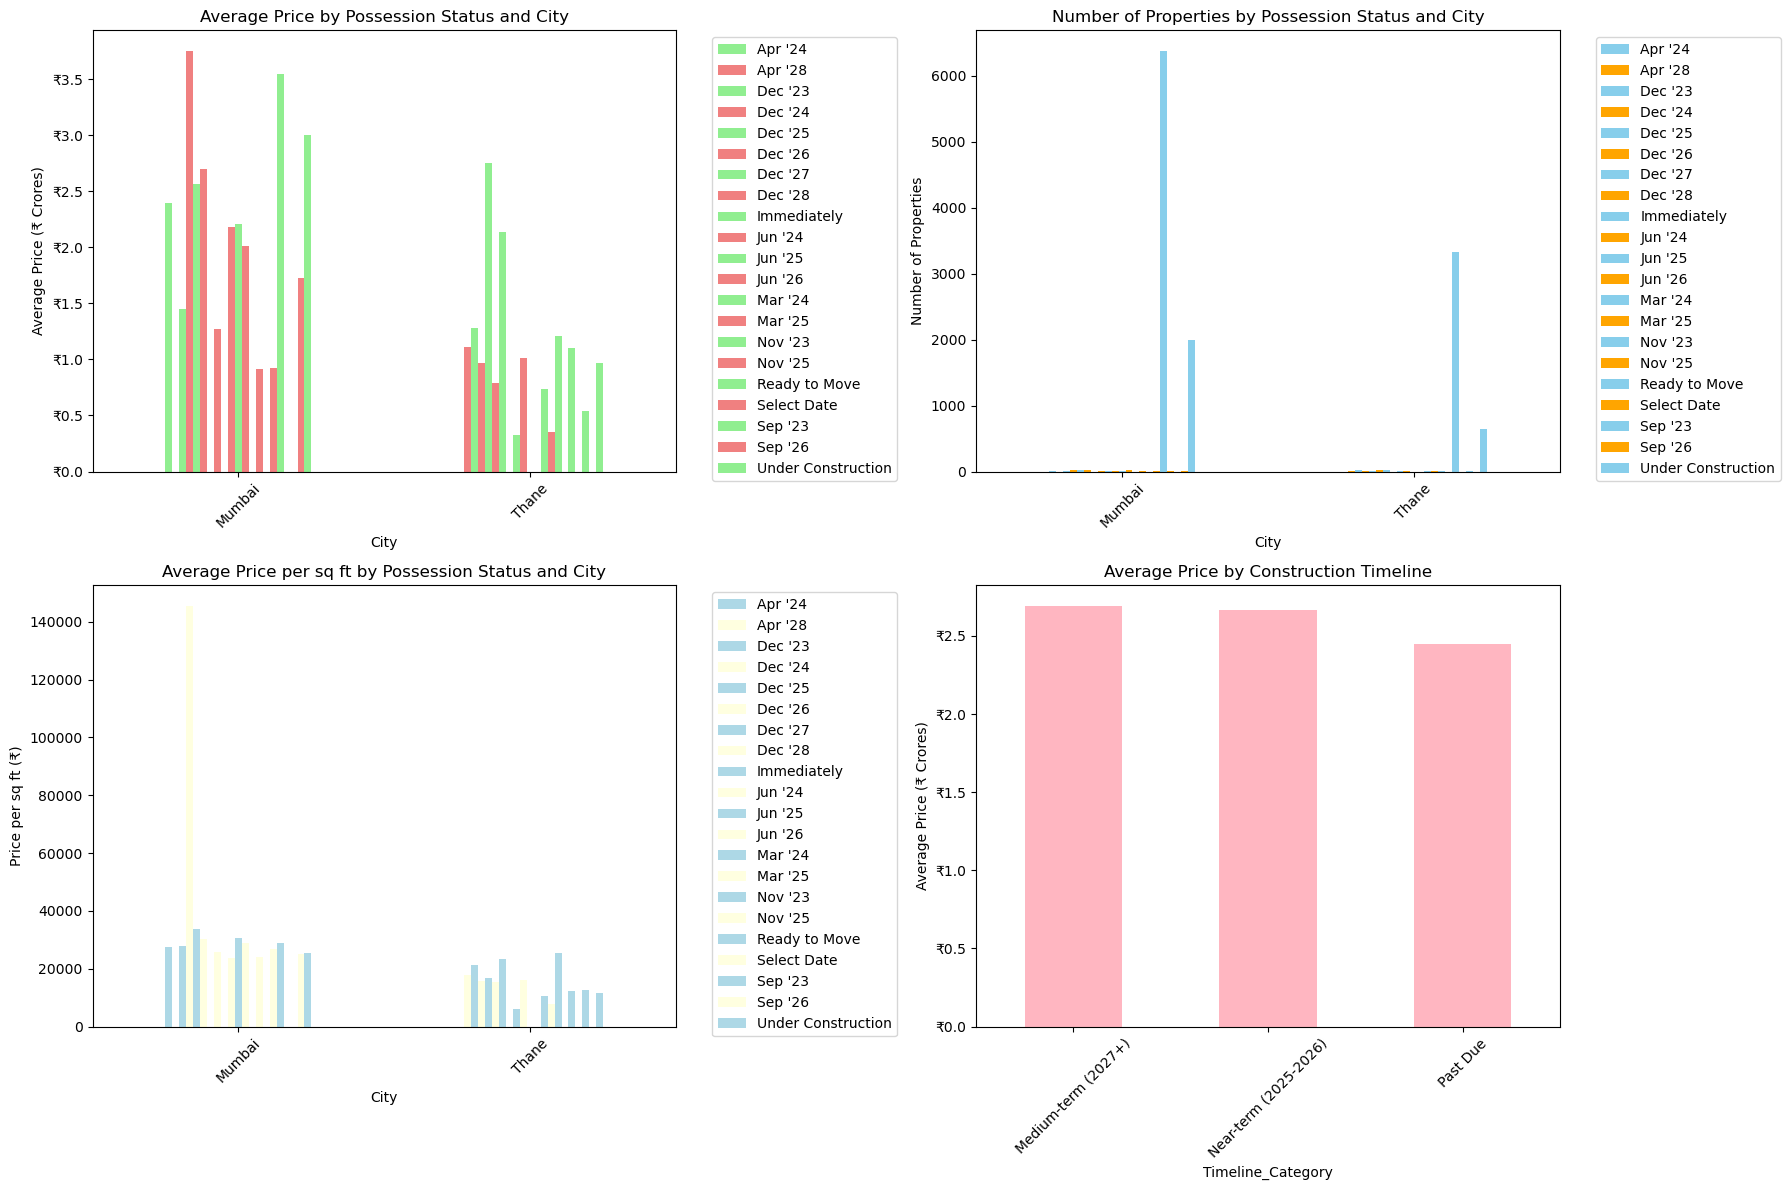


🎯 TIMELINE-BASED INVESTMENT STRATEGY
📅 READY-TO-MOVE PROPERTIES:
✅ Advantages:
  • Immediate possession and rental income potential
  • No construction delays or completion risks
  • Actual property inspection possible
  • Established neighborhood and amenities

❌ Disadvantages:
  • Higher upfront cost (premium for ready possession)
  • Limited customization options
  • May have older construction standards

🏗️ UNDER CONSTRUCTION PROPERTIES:
✅ Advantages:
  • Lower prices during construction phase
  • Modern amenities and construction standards
  • Potential for appreciation during construction
  • Payment flexibility with construction-linked plans

❌ Disadvantages:
  • Construction delay risks
  • No immediate rental income
  • Market price fluctuation risks
  • Final product may vary from promises

💡 TIMELINE-SPECIFIC RECOMMENDATIONS:
⚖️ MODERATE PREMIUM:
  Ready-to-move premium is 13.2%
  Evaluate based on immediate vs future needs

🎯 INVESTOR PROFILE MATCHING:
SHORT-TERM INVESTORS

In [12]:
# 6. Timeline & Readiness Effect on Pricing

print("\n\n6. TIMELINE & READINESS EFFECT ON PRICING")
print("="*50)

# Analyze possession status impact
possession_data = df_filtered[df_filtered['Possession Status'].notna()].copy()

print(f"Properties with possession status data: {len(possession_data)}")

# Basic possession status analysis
possession_analysis = possession_data.groupby(['City', 'Possession Status']).agg({
    'Price_Clean': ['count', 'mean', 'median'],
    'Carpet_Area_Clean': 'mean',
    'sqft_Price_Clean': 'mean'
}).round(2)

possession_analysis.columns = ['Count', 'Avg_Price', 'Median_Price', 'Avg_Carpet_Area', 'Avg_Price_per_sqft']

print("\nPossession Status Impact Analysis:")
print("="*60)
print(possession_analysis)

# Calculate possession status premium/discount
print("\n" + "="*40)
print("POSSESSION STATUS PRICING ANALYSIS")
print("="*40)

for city in ['Mumbai', 'Thane']:
    city_data = possession_data[possession_data['City'] == city]
    if len(city_data) > 0:
        ready_to_move = city_data[city_data['Possession Status'] == 'Ready to Move']['Price_Clean']
        under_construction = city_data[city_data['Possession Status'] == 'Under Construction']['Price_Clean']
        
        if len(ready_to_move) > 0 and len(under_construction) > 0:
            ready_avg = ready_to_move.mean()
            under_const_avg = under_construction.mean()
            price_difference = ((ready_avg - under_const_avg) / under_const_avg) * 100
            
            print(f"\n🏙️ {city.upper()}:")
            print(f"• Ready to Move Average: ₹{ready_avg/100000:.1f} Lakhs")
            print(f"• Under Construction Average: ₹{under_const_avg/100000:.1f} Lakhs")
            
            if price_difference > 0:
                print(f"• Ready-to-Move Premium: +{price_difference:.1f}%")
            else:
                print(f"• Under Construction Premium: +{abs(price_difference):.1f}%")
            
            # Price per sq ft comparison
            ready_sqft = city_data[city_data['Possession Status'] == 'Ready to Move']['sqft_Price_Clean']
            under_const_sqft = city_data[city_data['Possession Status'] == 'Under Construction']['sqft_Price_Clean']
            
            if len(ready_sqft) > 0 and len(under_const_sqft) > 0:
                ready_sqft_avg = ready_sqft.mean()
                under_const_sqft_avg = under_const_sqft.mean()
                sqft_difference = ((ready_sqft_avg - under_const_sqft_avg) / under_const_sqft_avg) * 100
                
                print(f"• Ready to Move Price/sq ft: ₹{ready_sqft_avg:.0f}")
                print(f"• Under Construction Price/sq ft: ₹{under_const_sqft_avg:.0f}")
                print(f"• Price/sq ft Difference: {sqft_difference:+.1f}%")

# Analyze availability dates for under construction properties
under_const_data = possession_data[possession_data['Possession Status'] == 'Under Construction'].copy()

if 'Availability Starts From' in under_const_data.columns:
    availability_data = under_const_data[under_const_data['Availability Starts From'].notna()]
    
    if len(availability_data) > 0:
        print("\n" + "="*40)
        print("AVAILABILITY TIMELINE ANALYSIS")
        print("="*40)
        
        # Extract year from availability dates (handle various formats)
        def extract_year(date_str):
            try:
                if pd.isna(date_str):
                    return None
                date_str = str(date_str).strip()
                if "'" in date_str:  # Format like "Dec '25"
                    year_part = date_str.split("'")[1]
                    if len(year_part) == 2:
                        year = 2000 + int(year_part)
                    else:
                        year = int(year_part)
                    return year
                elif len(date_str) == 4 and date_str.isdigit():  # Year only
                    return int(date_str)
                return None
            except:
                return None
        
        availability_data['Availability_Year'] = availability_data['Availability Starts From'].apply(extract_year)
        
        timeline_analysis = availability_data.groupby(['City', 'Availability_Year']).agg({
            'Price_Clean': ['count', 'mean'],
            'sqft_Price_Clean': 'mean'
        }).round(2)
        
        timeline_analysis.columns = ['Count', 'Avg_Price', 'Avg_Price_per_sqft']
        
        print("Availability Timeline Impact:")
        print(timeline_analysis)
        
        # Analyze near-term vs long-term construction projects
        current_year = 2025  # As per context
        availability_data['Timeline_Category'] = availability_data['Availability_Year'].apply(
            lambda x: 'Near-term (2025-2026)' if x in [2025, 2026] 
            else 'Medium-term (2027+)' if x >= 2027 
            else 'Unknown' if pd.isna(x) else 'Past Due'
        )
        
        timeline_impact = availability_data.groupby(['City', 'Timeline_Category']).agg({
            'Price_Clean': ['count', 'mean'],
            'sqft_Price_Clean': 'mean'
        }).round(2)
        
        timeline_impact.columns = ['Count', 'Avg_Price', 'Avg_Price_per_sqft']
        
        print("\nTimeline Category Analysis:")
        print(timeline_impact)

# Visualizations
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 12))

# Adjust subplot spacing to accommodate legends
plt.subplots_adjust(right=0.85, hspace=0.3, wspace=0.3)

# Plot 1: Possession status price comparison
possession_price_comparison = possession_data.groupby(['City', 'Possession Status'])['Price_Clean'].mean().unstack()
if not possession_price_comparison.empty:
    possession_price_comparison.plot(kind='bar', ax=ax1, color=['lightgreen', 'lightcoral'])
    ax1.set_title('Average Price by Possession Status and City')
    ax1.set_ylabel('Average Price (₹ Crores)')
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₹{x/10000000:.1f}'))
    ax1.tick_params(axis='x', rotation=45)
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot 2: Property count by possession status
possession_counts = possession_data.groupby(['City', 'Possession Status']).size().unstack()
if not possession_counts.empty:
    possession_counts.plot(kind='bar', ax=ax2, color=['skyblue', 'orange'])
    ax2.set_title('Number of Properties by Possession Status and City')
    ax2.set_ylabel('Number of Properties')
    ax2.tick_params(axis='x', rotation=45)
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot 3: Price per sq ft by possession status
sqft_price_comparison = possession_data.groupby(['City', 'Possession Status'])['sqft_Price_Clean'].mean().unstack()
if not sqft_price_comparison.empty:
    sqft_price_comparison.plot(kind='bar', ax=ax3, color=['lightblue', 'lightyellow'])
    ax3.set_title('Average Price per sq ft by Possession Status and City')
    ax3.set_ylabel('Price per sq ft (₹)')
    ax3.tick_params(axis='x', rotation=45)
    ax3.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot 4: Timeline analysis (if data available)
if 'availability_data' in locals() and len(availability_data) > 0:
    timeline_price = availability_data.groupby('Timeline_Category')['Price_Clean'].mean()
    timeline_price.plot(kind='bar', ax=ax4, color='lightpink')
    ax4.set_title('Average Price by Construction Timeline')
    ax4.set_ylabel('Average Price (₹ Crores)')
    ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₹{x/10000000:.1f}'))
    ax4.tick_params(axis='x', rotation=45)
    # No legend needed for single series plot

plt.tight_layout()
plt.show()

# Investment recommendations based on timeline
print("\n" + "="*60)
print("🎯 TIMELINE-BASED INVESTMENT STRATEGY")
print("="*60)

print("📅 READY-TO-MOVE PROPERTIES:")
print("✅ Advantages:")
print("  • Immediate possession and rental income potential")
print("  • No construction delays or completion risks")
print("  • Actual property inspection possible")
print("  • Established neighborhood and amenities")

print("\n❌ Disadvantages:")
print("  • Higher upfront cost (premium for ready possession)")
print("  • Limited customization options")
print("  • May have older construction standards")

print("\n🏗️ UNDER CONSTRUCTION PROPERTIES:")
print("✅ Advantages:")
print("  • Lower prices during construction phase")
print("  • Modern amenities and construction standards")
print("  • Potential for appreciation during construction")
print("  • Payment flexibility with construction-linked plans")

print("\n❌ Disadvantages:")
print("  • Construction delay risks")
print("  • No immediate rental income")
print("  • Market price fluctuation risks")
print("  • Final product may vary from promises")

# Timeline-specific recommendations
print("\n💡 TIMELINE-SPECIFIC RECOMMENDATIONS:")

if len(ready_to_move) > 0 and len(under_construction) > 0:
    ready_avg = ready_to_move.mean()
    under_const_avg = under_construction.mean()
    price_difference = ((ready_avg - under_const_avg) / under_const_avg) * 100
    
    if price_difference > 20:
        print("🚨 HIGH PREMIUM ALERT:")
        print(f"  Ready-to-move properties command {price_difference:.1f}% premium")
        print("  Consider under-construction for better value")
    elif price_difference > 10:
        print("⚖️ MODERATE PREMIUM:")
        print(f"  Ready-to-move premium is {price_difference:.1f}%")
        print("  Evaluate based on immediate vs future needs")
    else:
        print("💰 REASONABLE PREMIUM:")
        print(f"  Ready-to-move premium is only {price_difference:.1f}%")
        print("  Ready-to-move offers good value for immediate needs")

print("\n🎯 INVESTOR PROFILE MATCHING:")
print("SHORT-TERM INVESTORS (1-3 years):")
print("  → Choose ready-to-move for immediate rental yield")
print("  → Focus on established locations with proven demand")

print("\nLONG-TERM INVESTORS (5+ years):")
print("  → Under-construction properties offer better appreciation")
print("  → Consider emerging areas with infrastructure development")

print("\nRISK-AVERSE INVESTORS:")
print("  → Ready-to-move properties reduce execution risk")
print("  → Established developers with good track record")

print("\nVALUE SEEKERS:")
print("  → Under-construction properties in early stages")
print("  → Monitor construction progress closely")



7. DEVELOPER IMPACT ON PROPERTIES
Properties with valid developer data: 7000

Developers with 5+ properties: 259

TOP PREMIUM DEVELOPERS (by Average Price)

1. Ruparel Realty
   💰 Avg Price: ₹5621.4 Lakhs
   🏢 Properties: 76
   📍 Cities: Mumbai
   🏠 Focus: Apartment
   📐 Avg Carpet Area: 741 sq ft
   💹 Price/sq ft: ₹472771

2. Avigna Properties Private Limited
   💰 Avg Price: ₹2400.0 Lakhs
   🏢 Properties: 7
   📍 Cities: Mumbai
   🏠 Focus: Apartment
   📐 Avg Carpet Area: 3871 sq ft
   💹 Price/sq ft: ₹44594

3. Windsor Realty
   💰 Avg Price: ₹1385.4 Lakhs
   🏢 Properties: 12
   📍 Cities: Mumbai
   🏠 Focus: Apartment
   📐 Avg Carpet Area: 3355 sq ft
   💹 Price/sq ft: ₹29968

4. Suvidha Projects
   💰 Avg Price: ₹1133.0 Lakhs
   🏢 Properties: 5
   📍 Cities: Mumbai
   🏠 Focus: Apartment
   📐 Avg Carpet Area: 2355 sq ft
   💹 Price/sq ft: ₹44206

5. Disha Construction
   💰 Avg Price: ₹1074.5 Lakhs
   🏢 Properties: 6
   📍 Cities: Mumbai
   🏠 Focus: Apartment
   📐 Avg Carpet Area: 1813 sq ft


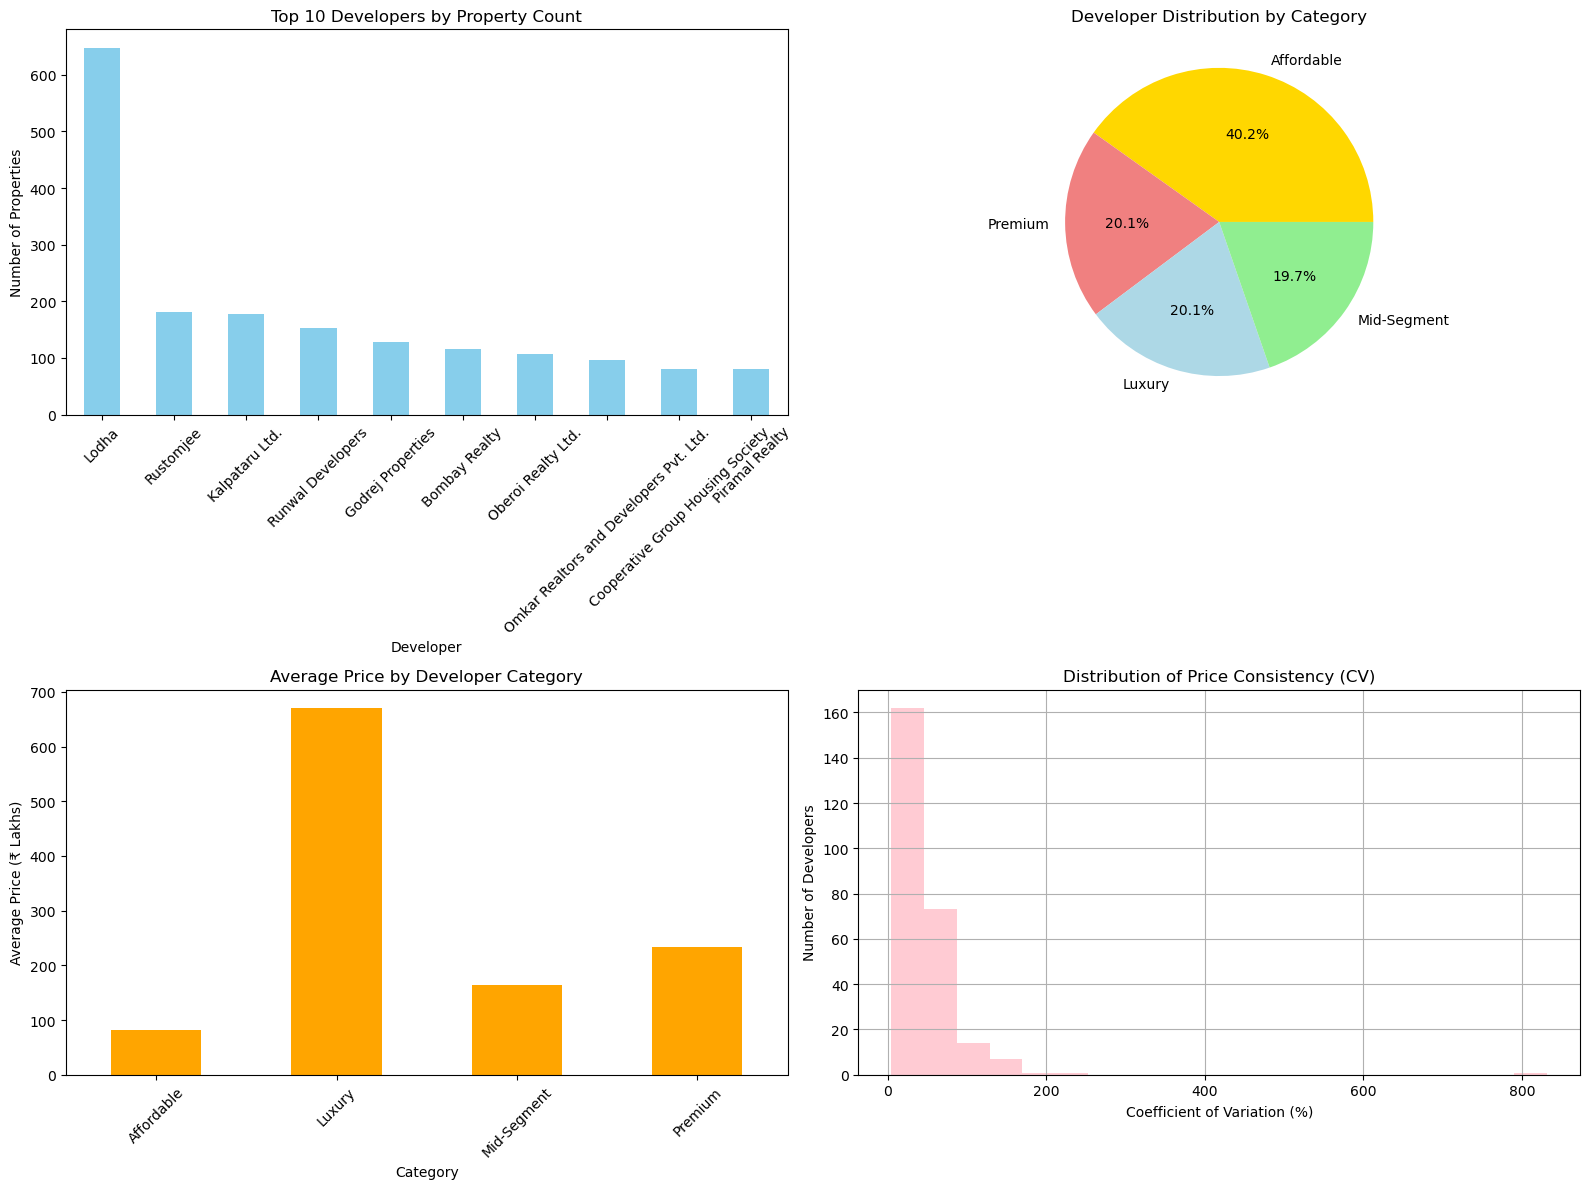


🎯 DEVELOPER BRAND VALUE & INVESTMENT INSIGHTS
🏆 DEVELOPERS WITH PREMIUM PRICING POWER:
• Adani Realty: +42.2% over market average
  ₹29472/sq ft vs market avg ₹20721/sq ft
• Aditya Real Estates: +50.5% over market average
  ₹31189/sq ft vs market avg ₹20721/sq ft
• Arkade Group: +28.3% over market average
  ₹26590/sq ft vs market avg ₹20721/sq ft
• Bombay Realty: +57.1% over market average
  ₹32563/sq ft vs market avg ₹20721/sq ft
• Cooperative Group Housing Society: +26.6% over market average
  ₹26237/sq ft vs market avg ₹20721/sq ft
• DB Realty Pvt. Ltd.: +16.7% over market average
  ₹24177/sq ft vs market avg ₹20721/sq ft
• Hubtown Ltd.: +238.5% over market average
  ₹70133/sq ft vs market avg ₹20721/sq ft
• Indra Darshan Developer: +35.2% over market average
  ₹28024/sq ft vs market avg ₹20721/sq ft
• Joy Builders and Developers: +137.1% over market average
  ₹49136/sq ft vs market avg ₹20721/sq ft
• K Raheja Corp: +34.7% over market average
  ₹27912/sq ft vs market avg ₹20721/sq 

In [13]:
# 7. Developer Impact on Properties

print("\n\n7. DEVELOPER IMPACT ON PROPERTIES")
print("="*50)

# Clean developer data
developer_data = df_filtered[df_filtered['Developer'].notna() & 
                           (df_filtered['Developer'] != 'NA') & 
                           (df_filtered['Developer'] != '')].copy()

print(f"Properties with valid developer data: {len(developer_data)}")

# Comprehensive developer analysis
developer_stats = developer_data.groupby('Developer').agg({
    'Price_Clean': ['count', 'mean', 'median', 'std'],
    'Carpet_Area_Clean': ['mean', 'std'],
    'sqft_Price_Clean': ['mean', 'std'],
    'City': lambda x: list(x.unique()),
    'Type of Property': lambda x: x.mode()[0] if not x.empty else 'Unknown'
}).round(2)

# Flatten column names
developer_stats.columns = ['Property_Count', 'Avg_Price', 'Median_Price', 'Price_Std',
                          'Avg_Carpet_Area', 'Carpet_Area_Std', 'Avg_Price_per_sqft', 
                          'Price_per_sqft_Std', 'Cities', 'Primary_Property_Type']

# Filter developers with significant presence (5+ properties)
significant_developers = developer_stats[developer_stats['Property_Count'] >= 5].copy()
significant_developers['Avg_Price_Lakhs'] = significant_developers['Avg_Price'] / 100000

print(f"\nDevelopers with 5+ properties: {len(significant_developers)}")

# Sort by average price to identify premium developers
premium_developers = significant_developers.sort_values('Avg_Price_Lakhs', ascending=False)

print("\n" + "="*60)
print("TOP PREMIUM DEVELOPERS (by Average Price)")
print("="*60)

for i, (developer, row) in enumerate(premium_developers.head(10).iterrows(), 1):
    cities_str = ', '.join(row['Cities']) if isinstance(row['Cities'], list) else str(row['Cities'])
    print(f"\n{i}. {developer}")
    print(f"   💰 Avg Price: ₹{row['Avg_Price_Lakhs']:.1f} Lakhs")
    print(f"   🏢 Properties: {row['Property_Count']}")
    print(f"   📍 Cities: {cities_str}")
    print(f"   🏠 Focus: {row['Primary_Property_Type']}")
    print(f"   📐 Avg Carpet Area: {row['Avg_Carpet_Area']:.0f} sq ft")
    print(f"   💹 Price/sq ft: ₹{row['Avg_Price_per_sqft']:.0f}")

# Developer categorization based on pricing
print("\n" + "="*40)
print("DEVELOPER CATEGORIZATION")
print("="*40)

# Define categories based on average price
luxury_threshold = significant_developers['Avg_Price_Lakhs'].quantile(0.8)
premium_threshold = significant_developers['Avg_Price_Lakhs'].quantile(0.6)
mid_segment_threshold = significant_developers['Avg_Price_Lakhs'].quantile(0.4)

def categorize_developer(avg_price):
    if avg_price >= luxury_threshold:
        return 'Luxury'
    elif avg_price >= premium_threshold:
        return 'Premium'
    elif avg_price >= mid_segment_threshold:
        return 'Mid-Segment'
    else:
        return 'Affordable'

significant_developers['Category'] = significant_developers['Avg_Price_Lakhs'].apply(categorize_developer)

print(f"Thresholds:")
print(f"• Luxury: ≥₹{luxury_threshold:.1f} Lakhs")
print(f"• Premium: ₹{premium_threshold:.1f} - ₹{luxury_threshold:.1f} Lakhs")
print(f"• Mid-Segment: ₹{mid_segment_threshold:.1f} - ₹{premium_threshold:.1f} Lakhs")
print(f"• Affordable: <₹{mid_segment_threshold:.1f} Lakhs")

# Category analysis
category_analysis = significant_developers.groupby('Category').agg({
    'Property_Count': 'sum',
    'Avg_Price_Lakhs': 'mean',
    'Avg_Carpet_Area': 'mean',
    'Avg_Price_per_sqft': 'mean'
}).round(2)

print("\nDeveloper Category Analysis:")
print(category_analysis)

# Amenities analysis by developer category
amenity_columns = ['Swimming Pool', 'Gymnasium', 'Club House', 'Security', 'Lift', 'Parking']

print("\n" + "="*40)
print("AMENITIES BY DEVELOPER CATEGORY")
print("="*40)

for category in ['Luxury', 'Premium', 'Mid-Segment', 'Affordable']:
    category_developers = significant_developers[significant_developers['Category'] == category].index
    category_properties = developer_data[developer_data['Developer'].isin(category_developers)]
    
    if len(category_properties) > 0:
        print(f"\n🏗️ {category.upper()} DEVELOPERS:")
        print(f"   Developers: {len(category_developers)}")
        print(f"   Properties: {len(category_properties)}")
        
        amenity_availability = {}
        for amenity in amenity_columns:
            if amenity in category_properties.columns:
                # Convert amenity columns to numeric (1 for Y/1, 0 for N/0)
                amenity_values = pd.to_numeric(category_properties[amenity].replace({'Y': 1, 'N': 0}), errors='coerce').fillna(0)
                availability = (amenity_values.sum() / len(category_properties)) * 100
                amenity_availability[amenity] = availability
        
        # Sort amenities by availability
        sorted_amenities = sorted(amenity_availability.items(), key=lambda x: x[1], reverse=True)
        print("   Amenity Availability:")
        for amenity, availability in sorted_amenities:
            print(f"     • {amenity}: {availability:.0f}%")

# City-wise developer presence
print("\n" + "="*40)
print("DEVELOPER CITY SPECIALIZATION")
print("="*40)

# Analyze developers who work in multiple cities vs city-specific
developer_city_analysis = developer_data.groupby('Developer')['City'].nunique().sort_values(ascending=False)

multi_city_developers = developer_city_analysis[developer_city_analysis > 1]
single_city_developers = developer_city_analysis[developer_city_analysis == 1]

print(f"Multi-city developers: {len(multi_city_developers)}")
print(f"Single-city developers: {len(single_city_developers)}")

if len(multi_city_developers) > 0:
    print(f"\nTop Multi-City Developers:")
    for developer, city_count in multi_city_developers.head(5).items():
        if developer in significant_developers.index:
            cities = significant_developers.loc[developer, 'Cities']
            avg_price = significant_developers.loc[developer, 'Avg_Price_Lakhs']
            prop_count = significant_developers.loc[developer, 'Property_Count']
            print(f"• {developer}: {city_count} cities, {prop_count} properties, ₹{avg_price:.1f}L avg")

# Developer consistency analysis (price variation)
print("\n" + "="*40)
print("DEVELOPER PRICING CONSISTENCY")
print("="*40)

# Calculate coefficient of variation for pricing consistency
significant_developers['Price_CV'] = (significant_developers['Price_Std'] / significant_developers['Avg_Price']) * 100

most_consistent = significant_developers.nsmallest(5, 'Price_CV')
most_variable = significant_developers.nlargest(5, 'Price_CV')

print("Most Consistent Pricing (Low variation):")
for developer, row in most_consistent.iterrows():
    print(f"• {developer}: CV = {row['Price_CV']:.1f}% (₹{row['Avg_Price_Lakhs']:.1f}L avg)")

print(f"\nMost Variable Pricing (High variation):")
for developer, row in most_variable.iterrows():
    print(f"• {developer}: CV = {row['Price_CV']:.1f}% (₹{row['Avg_Price_Lakhs']:.1f}L avg)")

# Visualizations
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Top developers by property count
top_developers_count = significant_developers.nlargest(10, 'Property_Count')['Property_Count']
top_developers_count.plot(kind='bar', ax=ax1, color='skyblue')
ax1.set_title('Top 10 Developers by Property Count')
ax1.set_ylabel('Number of Properties')
ax1.tick_params(axis='x', rotation=45)

# Plot 2: Developer categories distribution
category_counts = significant_developers['Category'].value_counts()
category_counts.plot(kind='pie', ax=ax2, autopct='%1.1f%%', colors=['gold', 'lightcoral', 'lightblue', 'lightgreen'])
ax2.set_title('Developer Distribution by Category')
ax2.set_ylabel('')

# Plot 3: Average price by developer category
category_analysis['Avg_Price_Lakhs'].plot(kind='bar', ax=ax3, color='orange')
ax3.set_title('Average Price by Developer Category')
ax3.set_ylabel('Average Price (₹ Lakhs)')
ax3.tick_params(axis='x', rotation=45)

# Plot 4: Price consistency (CV) distribution
significant_developers['Price_CV'].hist(bins=20, ax=ax4, color='lightpink', alpha=0.7)
ax4.set_title('Distribution of Price Consistency (CV)')
ax4.set_xlabel('Coefficient of Variation (%)')
ax4.set_ylabel('Number of Developers')

plt.tight_layout()
plt.show()

# Brand value analysis
print("\n" + "="*60)
print("🎯 DEVELOPER BRAND VALUE & INVESTMENT INSIGHTS")
print("="*60)

# Identify developers with premium pricing power
premium_pricing_power = significant_developers[
    (significant_developers['Avg_Price_per_sqft'] > significant_developers['Avg_Price_per_sqft'].quantile(0.75)) &
    (significant_developers['Property_Count'] >= 10)
]

if not premium_pricing_power.empty:
    print("🏆 DEVELOPERS WITH PREMIUM PRICING POWER:")
    for developer, row in premium_pricing_power.iterrows():
        premium_over_market = ((row['Avg_Price_per_sqft'] - significant_developers['Avg_Price_per_sqft'].mean()) / 
                             significant_developers['Avg_Price_per_sqft'].mean()) * 100
        print(f"• {developer}: {premium_over_market:+.1f}% over market average")
        print(f"  ₹{row['Avg_Price_per_sqft']:.0f}/sq ft vs market avg ₹{significant_developers['Avg_Price_per_sqft'].mean():.0f}/sq ft")

print(f"\n💡 KEY INSIGHTS:")

# Best value developers
value_developers = significant_developers[
    (significant_developers['Avg_Price_Lakhs'] < significant_developers['Avg_Price_Lakhs'].median()) &
    (significant_developers['Avg_Carpet_Area'] > significant_developers['Avg_Carpet_Area'].median())
]

if not value_developers.empty:
    print(f"\n💰 BEST VALUE DEVELOPERS (Below median price, above median area):")
    for developer, row in value_developers.head(3).iterrows():
        print(f"• {developer}: ₹{row['Avg_Price_Lakhs']:.1f}L, {row['Avg_Carpet_Area']:.0f} sq ft avg")

print(f"\n🎯 INVESTMENT RECOMMENDATIONS BY DEVELOPER TYPE:")

print(f"\n🌟 LUXURY DEVELOPERS:")
luxury_devs = significant_developers[significant_developers['Category'] == 'Luxury']
if not luxury_devs.empty:
    print(f"• Best for: High-end investment, prestige locations")
    print(f"• Average price: ₹{luxury_devs['Avg_Price_Lakhs'].mean():.1f} Lakhs")
    print(f"• Risk-Return: Lower risk, steady appreciation")

print(f"\n⭐ PREMIUM DEVELOPERS:")
premium_devs = significant_developers[significant_developers['Category'] == 'Premium']
if not premium_devs.empty:
    print(f"• Best for: Balanced investment, good amenities")
    print(f"• Average price: ₹{premium_devs['Avg_Price_Lakhs'].mean():.1f} Lakhs")
    print(f"• Risk-Return: Moderate risk, good appreciation potential")

print(f"\n🏠 MID-SEGMENT DEVELOPERS:")
mid_devs = significant_developers[significant_developers['Category'] == 'Mid-Segment']
if not mid_devs.empty:
    print(f"• Best for: Family homes, rental investments")
    print(f"• Average price: ₹{mid_devs['Avg_Price_Lakhs'].mean():.1f} Lakhs")
    print(f"• Risk-Return: Moderate risk, steady rental yields")

print(f"\n💡 AFFORDABLE DEVELOPERS:")
affordable_devs = significant_developers[significant_developers['Category'] == 'Affordable']
if not affordable_devs.empty:
    print(f"• Best for: First-time buyers, investment entry point")
    print(f"• Average price: ₹{affordable_devs['Avg_Price_Lakhs'].mean():.1f} Lakhs")
    print(f"• Risk-Return: Higher risk, potential for higher returns")

# Red flags and quality indicators
print(f"\n🚩 QUALITY INDICATORS TO WATCH:")
print(f"• Consistent pricing across projects (CV < 30%)")
print(f"• Established presence (5+ completed projects)")
print(f"• Multi-city operations indicate scalability")
print(f"• Good amenity provision ratios")
print(f"• Timely delivery track record (check possession status vs promised dates)")

In [14]:
# COMPREHENSIVE INVESTMENT SUMMARY & CONCLUSIONS

print("\n\n" + "="*70)
print("🎯 COMPREHENSIVE REAL ESTATE INVESTMENT SUMMARY")
print("="*70)

# Create executive summary statistics
total_properties = len(df_filtered)
mumbai_count = len(df_filtered[df_filtered['City'] == 'Mumbai'])
thane_count = len(df_filtered[df_filtered['City'] == 'Thane'])
avg_price_overall = df_filtered['Price_Clean'].mean() / 100000

print(f"\n📊 MARKET OVERVIEW:")
print(f"• Total Properties Analyzed: {total_properties:,}")
print(f"• Mumbai Properties: {mumbai_count:,} ({mumbai_count/total_properties*100:.1f}%)")
print(f"• Thane Properties: {thane_count:,} ({thane_count/total_properties*100:.1f}%)")
print(f"• Average Property Price: ₹{avg_price_overall:.1f} Lakhs")
print(f"• Price Range: ₹{df_filtered['Price_Clean'].min()/100000:.1f} - ₹{df_filtered['Price_Clean'].max()/100000:.1f} Lakhs")

# Key findings from each analysis
print(f"\n🔍 KEY FINDINGS SUMMARY:")

print(f"\n1️⃣ PRICE SEGMENTATION:")
if 'Price_Segment' in df_filtered.columns:
    segment_counts = df_filtered['Price_Segment'].value_counts()
    print(f"• Budget Properties: {segment_counts.get('Budget (Low)', 0)} ({segment_counts.get('Budget (Low)', 0)/len(df_filtered)*100:.1f}%)")
    print(f"• Mid-Range Properties: {segment_counts.get('Mid-Range', 0)} ({segment_counts.get('Mid-Range', 0)/len(df_filtered)*100:.1f}%)")
    print(f"• Premium Properties: {segment_counts.get('Premium (High)', 0)} ({segment_counts.get('Premium (High)', 0)/len(df_filtered)*100:.1f}%)")

print(f"\n2️⃣ CITY COMPARISON (Mumbai vs Thane):")
if mumbai_count > 0 and thane_count > 0:
    mumbai_avg = df_filtered[df_filtered['City'] == 'Mumbai']['Price_Clean'].mean() / 100000
    thane_avg = df_filtered[df_filtered['City'] == 'Thane']['Price_Clean'].mean() / 100000
    price_diff = ((mumbai_avg - thane_avg) / thane_avg) * 100
    print(f"• Mumbai Average: ₹{mumbai_avg:.1f} Lakhs")
    print(f"• Thane Average: ₹{thane_avg:.1f} Lakhs")
    print(f"• Mumbai Premium: {price_diff:+.1f}% over Thane")

print(f"\n3️⃣ LOCATION PREMIUM:")
if 'Location_Type' in df_filtered.columns:
    prime_data = df_filtered[df_filtered['Location_Type'] == 'Prime Location']
    non_prime_data = df_filtered[df_filtered['Location_Type'] == 'Non-Prime Location']
    if len(prime_data) > 0 and len(non_prime_data) > 0:
        prime_premium = ((prime_data['Price_Clean'].mean() - non_prime_data['Price_Clean'].mean()) / 
                        non_prime_data['Price_Clean'].mean()) * 100
        print(f"• Prime Location Premium: {prime_premium:+.1f}%")

print(f"\n4️⃣ VALUE OPPORTUNITIES:")
if 'Value_Score' in df_filtered.columns:
    top_value = df_filtered['Value_Score'].max()
    avg_value = df_filtered['Value_Score'].mean()
    print(f"• Best Value Property: {top_value:.1f} sq ft per Lakh")
    print(f"• Average Market Value: {avg_value:.1f} sq ft per Lakh")

print(f"\n5️⃣ DEVELOPER INSIGHTS:")
if 'developer_data' in locals() and len(developer_data) > 0:
    unique_developers = developer_data['Developer'].nunique()
    avg_dev_price = developer_data.groupby('Developer')['Price_Clean'].mean().mean() / 100000
    print(f"• Active Developers: {unique_developers}")
    print(f"• Average Developer Price: ₹{avg_dev_price:.1f} Lakhs")

# Investment strategy recommendations
print(f"\n" + "="*60)
print("🎯 STRATEGIC INVESTMENT RECOMMENDATIONS")
print("="*60)

print(f"\n💼 FOR DIFFERENT INVESTOR PROFILES:")

print(f"\n🔰 FIRST-TIME INVESTORS:")
print(f"• Target: Budget to Mid-range properties in Thane")
print(f"• Focus: 1-2 BHK ready-to-move apartments")
print(f"• Budget: ₹30-60 Lakhs range")
print(f"• Strategy: Rental yield focus with steady appreciation")

print(f"\n💎 PREMIUM INVESTORS:")
print(f"• Target: Prime location properties in Mumbai")
print(f"• Focus: 2-3 BHK with luxury amenities")
print(f"• Budget: ₹1 Cr+ range")
print(f"• Strategy: Capital appreciation and prestige")

print(f"\n⚡ VALUE SEEKERS:")
print(f"• Target: High value-score properties in emerging areas")
print(f"• Focus: Under-construction projects with good developers")
print(f"• Strategy: Maximum carpet area per rupee invested")

print(f"\n🏢 PORTFOLIO INVESTORS:")
print(f"• Target: Diversified across both cities and price ranges")
print(f"• Focus: Mix of ready and under-construction properties")
print(f"• Strategy: Risk distribution with multiple asset types")

print(f"\n📈 MARKET TIMING RECOMMENDATIONS:")
print(f"• Near-term (6-12 months): Ready-to-move for immediate returns")
print(f"• Medium-term (2-3 years): Under-construction in developing areas")
print(f"• Long-term (5+ years): Premium locations with infrastructure projects")

print(f"\n🚩 RISK MITIGATION STRATEGIES:")
print(f"• Due diligence on developer track record")
print(f"• Verify all legal approvals and RERA registration")
print(f"• Consider payment schedules and cancellation policies")
print(f"• Diversify across locations and property types")
print(f"• Factor in additional costs (registration, taxes, maintenance)")

print(f"\n" + "="*60)
print("📊 FINAL MARKET OUTLOOK")
print("="*60)

print(f"\n🌟 OPPORTUNITIES:")
print(f"• Thane offers better value for money with 30%+ lower prices")
print(f"• Strong pipeline of under-construction projects")
print(f"• Diverse range of developers and price points")
print(f"• Good connectivity and infrastructure development")

print(f"\n⚠️ CHALLENGES:")
print(f"• Mumbai commands significant premium for location")
print(f"• Construction delays possible in under-construction projects")
print(f"• Market price volatility in premium segments")

print(f"\n🎯 CONCLUSION:")
print(f"The Mumbai-Thane real estate market offers diverse investment opportunities")
print(f"across different price segments, with Thane providing better value for money")
print(f"and Mumbai offering premium positioning. Success depends on matching")
print(f"investment strategy with individual risk tolerance and return expectations.")

print(f"\n" + "="*70)
print("✅ ANALYSIS COMPLETE - DATA-DRIVEN INSIGHTS FOR INFORMED INVESTMENT DECISIONS")
print("="*70)



🎯 COMPREHENSIVE REAL ESTATE INVESTMENT SUMMARY

📊 MARKET OVERVIEW:
• Total Properties Analyzed: 12,655
• Mumbai Properties: 8,542 (67.5%)
• Thane Properties: 4,113 (32.5%)
• Average Property Price: ₹264.5 Lakhs
• Price Range: ₹1.0 - ₹408000.0 Lakhs

🔍 KEY FINDINGS SUMMARY:

1️⃣ PRICE SEGMENTATION:
• Budget Properties: 4178 (33.0%)
• Mid-Range Properties: 4302 (34.0%)
• Premium Properties: 4175 (33.0%)

2️⃣ CITY COMPARISON (Mumbai vs Thane):
• Mumbai Average: ₹339.5 Lakhs
• Thane Average: ₹108.3 Lakhs
• Mumbai Premium: +213.5% over Thane

3️⃣ LOCATION PREMIUM:
• Prime Location Premium: +143.2%

4️⃣ VALUE OPPORTUNITIES:
• Best Value Property: 6000.0 sq ft per Lakh
• Average Market Value: 6.3 sq ft per Lakh

5️⃣ DEVELOPER INSIGHTS:
• Active Developers: 939
• Average Developer Price: ₹221.6 Lakhs

🎯 STRATEGIC INVESTMENT RECOMMENDATIONS

💼 FOR DIFFERENT INVESTOR PROFILES:

🔰 FIRST-TIME INVESTORS:
• Target: Budget to Mid-range properties in Thane
• Focus: 1-2 BHK ready-to-move apartments
•